In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv('/content/pesticides (1).csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (4349, 7)


In [3]:
df = pd.read_csv('/content/rainfall.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (6727, 3)


In [4]:
df = pd.read_csv('/content/temp.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (71311, 3)


In [5]:
df = pd.read_csv('/content/yield.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (56717, 12)


In [6]:
df = pd.read_csv('/content/yield_df.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (28242, 8)


In [7]:
df.head()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [8]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/16a8CFmGE8zee1Jz-rJ_AgCqP0II73qOqS5TUfIQnDe8/edit#gid=0


In [9]:
print("Year range:")
print(df['Year'].min(), "to", df['Year'].max())

print("\nAll available years:")
print(sorted(df['Year'].unique()))

print("\nNumber of countries/areas:")
print(df['Area'].nunique())

print("\nCountries/areas:")
print(sorted(df['Area'].unique()))

Year range:
1990 to 2013

All available years:
[np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013)]

Number of countries/areas:
101

Countries/areas:
['Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cameroon', 'Canada', 'Central African Republic', 'Chile', 'Colombia', 'Croatia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Eritrea', 'Estonia', 'Finland', 'France', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'India', 'Indonesia', 'Iraq', 'I

In [10]:
# Countries completely held out for testing
test_countries = ['Brazil', 'Mexico', 'Argentina']

# All other countries are used for training
train_countries = [
    country for country in df['Area'].unique()
    if country not in test_countries
]

# Training data: earlier years + training countries
train_data = df[
    (df['Area'].isin(train_countries)) &
    (df['Year'].between(1990, 2004))
].copy()

# Testing data: later years + completely unseen countries
test_data = df[
    (df['Area'].isin(test_countries)) &
    (df['Year'].between(2005, 2013))
].copy()

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

print("\nNumber of training countries:", train_data['Area'].nunique())
print("Training years:", train_data['Year'].min(), "to", train_data['Year'].max())

print("\nTesting countries:", sorted(test_data['Area'].unique()))
print("Testing years:", test_data['Year'].min(), "to", test_data['Year'].max())

Training shape: (14521, 8)
Testing shape: (1611, 8)

Number of training countries: 96
Training years: 1990 to 2004

Testing countries: ['Argentina', 'Brazil', 'Mexico']
Testing years: 2005 to 2013


In [11]:
print("TRAINING COUNTRIES:")
print(f"Number of countries: {train_data['Area'].nunique()}")

print("\nTESTING COUNTRIES:")
print(sorted(test_data['Area'].unique()))

print("\nTRAINING YEARS:")
print(sorted(train_data['Year'].unique()))

print("\nTESTING YEARS:")
print(sorted(test_data['Year'].unique()))

print("\nCountry overlap:")
print(set(train_data['Area']) & set(test_data['Area']))

print("\nYear overlap:")
print(set(train_data['Year']) & set(test_data['Year']))

TRAINING COUNTRIES:
Number of countries: 96

TESTING COUNTRIES:
['Argentina', 'Brazil', 'Mexico']

TRAINING YEARS:
[np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2004)]

TESTING YEARS:
[np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013)]

Country overlap:
set()

Year overlap:
set()


In [12]:
# Remove unnecessary index column
train_data = train_data.drop(columns=['Unnamed: 0'], errors='ignore')
test_data = test_data.drop(columns=['Unnamed: 0'], errors='ignore')

# Separate input features and target
X_train = train_data.drop(columns=['hg/ha_yield'])
y_train = train_data['hg/ha_yield']

X_test = test_data.drop(columns=['hg/ha_yield'])
y_test = test_data['hg/ha_yield']

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (14521, 6)
y_train shape: (14521,)
X_test shape: (1611, 6)
y_test shape: (1611,)


In [13]:
from sklearn.preprocessing import OneHotEncoder

# Select features
X_train = train_data[
    ['Item', 'Year',
     'average_rain_fall_mm_per_year',
     'pesticides_tonnes',
     'avg_temp']
].copy()

y_train = train_data['hg/ha_yield']

X_test = test_data[
    ['Item', 'Year',
     'average_rain_fall_mm_per_year',
     'pesticides_tonnes',
     'avg_temp']
].copy()

y_test = test_data['hg/ha_yield']


# One-hot encode Item
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

train_item_encoded = encoder.fit_transform(X_train[['Item']])
test_item_encoded = encoder.transform(X_test[['Item']])


# Create encoded DataFrames
encoded_columns = encoder.get_feature_names_out(['Item'])

train_item_df = pd.DataFrame(
    train_item_encoded,
    columns=encoded_columns,
    index=X_train.index
)

test_item_df = pd.DataFrame(
    test_item_encoded,
    columns=encoded_columns,
    index=X_test.index
)


# Remove original Item column
X_train = X_train.drop(columns=['Item'])
X_test = X_test.drop(columns=['Item'])

# Add encoded Item columns
X_train = pd.concat([X_train, train_item_df], axis=1)
X_test = pd.concat([X_test, test_item_df], axis=1)

print("Encoding completed successfully!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Encoding completed successfully!
X_train shape: (14521, 14)
X_test shape: (1611, 14)


In [14]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nSame columns:", list(X_train.columns) == list(X_test.columns))

print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

print("\nAll features numeric:",
      all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train.dtypes))

X_train shape: (14521, 14)
X_test shape: (1611, 14)

Same columns: True

Missing values in X_train: 0
Missing values in X_test: 0

All features numeric: True


In [15]:
print("Same columns:", list(X_train.columns) == list(X_test.columns))

print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

print(
    "All features numeric:",
    all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train.dtypes)
)

Same columns: True
Missing values in X_train: 0
Missing values in X_test: 0
All features numeric: True


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Create and train the model
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Predict on unseen countries + later years
y_pred_lr = model_lr.predict(X_test)

# Evaluation
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
mape_lr = mean_absolute_percentage_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("-------------------------")
print("MAE  :", mae_lr)
print("MSE  :", mse_lr)
print("RMSE :", rmse_lr)
print("MAPE :", mape_lr)
print("R²   :", r2_lr)

Linear Regression Results
-------------------------
MAE  : 104902.29739453978
MSE  : 15701836274.005499
RMSE : 125306.96817817235
MAPE : 2.2972388331468823
R²   : -1.524422410587333


In [17]:
# Make predictions on the test data
y_pred_lr = model_lr.predict(X_test)

# Show first 10 predictions
print("Predicted values:")
print(y_pred_lr[:10])

print("\nActual values:")
print(y_test.values[:10])

Predicted values:
[192134.10504683 191022.92825845  71855.42948857  70744.2527002
 223331.0071326  222219.83034423  80042.88196538  78931.70517701
  59231.24087087  58120.0640825 ]

Actual values:
[100000 100000  73587  73587 283917 283917  60165  60165  51872  51872]


In [18]:
from sklearn.ensemble import RandomForestRegressor

# Create and train the model
model_rf = RandomForestRegressor(
    random_state=42
)

model_rf.fit(X_train, y_train)

# Predict on unseen countries + later years
y_pred_rf = model_rf.predict(X_test)

# Evaluation
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
mape_rf = mean_absolute_percentage_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE  :", mae_rf)
print("MSE  :", mse_rf)
print("RMSE :", rmse_rf)
print("MAPE :", mape_rf)
print("R²   :", r2_rf)

Random Forest Results
---------------------
MAE  : 34926.98888888888
MSE  : 2655512256.675895
RMSE : 51531.66266166749
MAPE : 0.4037378324602958
R²   : 0.5730668352821965


In [19]:
from sklearn.ensemble import GradientBoostingRegressor

# Create and train the model
model_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model_gb.fit(X_train, y_train)

# Predict on unseen countries + later years
y_pred_gb = model_gb.predict(X_test)

# Evaluation
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
mape_gb = mean_absolute_percentage_error(y_test, y_pred_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE  :", mae_gb)
print("MSE  :", mse_gb)
print("RMSE :", rmse_gb)
print("MAPE :", mape_gb)
print("R²   :", r2_gb)

Gradient Boosting Results
-------------------------
MAE  : 29200.892348991434
MSE  : 1826309253.2822366
RMSE : 42735.33962989222
MAPE : 0.33655701682483935
R²   : 0.7063798190736961


In [20]:
from xgboost import XGBRegressor

# Create and train the model
model_xgb = XGBRegressor(
    random_state=42
)

model_xgb.fit(X_train, y_train)

# Predict on unseen countries + later years
y_pred_xgb = model_xgb.predict(X_test)

# Evaluation
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
mape_xgb = mean_absolute_percentage_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Results")
print("----------------")
print("MAE  :", mae_xgb)
print("MSE  :", mse_xgb)
print("RMSE :", rmse_xgb)
print("MAPE :", mape_xgb)
print("R²   :", r2_xgb)

XGBoost Results
----------------
MAE  : 28816.44921875
MSE  : 1769912320.0
RMSE : 42070.32588416686
MAPE : 0.37100455164909363
R²   : 0.7154468894004822


In [21]:
from sklearn.neighbors import KNeighborsRegressor

# Create and train the model
model_knn = KNeighborsRegressor(
    n_neighbors=5
)

model_knn.fit(X_train, y_train)

# Predict on unseen countries + later years
y_pred_knn = model_knn.predict(X_test)

# Evaluation
mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mse_knn)
mape_knn = mean_absolute_percentage_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)

print("KNN Results")
print("-----------")
print("MAE  :", mae_knn)
print("MSE  :", mse_knn)
print("RMSE :", rmse_knn)
print("MAPE :", mape_knn)
print("R²   :", r2_knn)

KNN Results
-----------
MAE  : 67988.65251396649
MSE  : 7535859773.966132
RMSE : 86809.32999376353
MAPE : 1.5066531420867308
R²   : -0.21155850592695047


In [22]:
from sklearn.tree import DecisionTreeRegressor

# Create and train the model
model_dt = DecisionTreeRegressor(
    random_state=42
)

model_dt.fit(X_train, y_train)

# Predict on unseen countries + later years
y_pred_dt = model_dt.predict(X_test)

# Evaluation
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
mape_dt = mean_absolute_percentage_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("---------------------")
print("MAE  :", mae_dt)
print("MSE  :", mse_dt)
print("RMSE :", rmse_dt)
print("MAPE :", mape_dt)
print("R²   :", r2_dt)

Decision Tree Results
---------------------
MAE  : 43967.1148355059
MSE  : 3887111577.428926
RMSE : 62346.70462365213
MAPE : 0.5044993532619064
R²   : 0.37505961676851307


In [23]:
from sklearn.ensemble import BaggingRegressor

# Create and train the model
model_bag = BaggingRegressor(
    n_estimators=150,
    random_state=42
)

model_bag.fit(X_train, y_train)

# Predict on unseen countries + later years
y_pred_bag = model_bag.predict(X_test)

# Evaluation
mae_bag = mean_absolute_error(y_test, y_pred_bag)
mse_bag = mean_squared_error(y_test, y_pred_bag)
rmse_bag = np.sqrt(mse_bag)
mape_bag = mean_absolute_percentage_error(y_test, y_pred_bag)
r2_bag = r2_score(y_test, y_pred_bag)

print("Bagging Regressor Results")
print("-------------------------")
print("MAE  :", mae_bag)
print("MSE  :", mse_bag)
print("RMSE :", rmse_bag)
print("MAPE :", mape_bag)
print("R²   :", r2_bag)

Bagging Regressor Results
-------------------------
MAE  : 35085.77776950134
MSE  : 2738610750.861766
RMSE : 52331.73751044165
MAPE : 0.4044678482884087
R²   : 0.559706888244909


In [24]:
# Model comparison
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost',
        'KNN',
        'Decision Tree',
        'Bagging Regressor'
    ],
    'MAE': [
        mae_lr,
        mae_rf,
        mae_gb,
        mae_xgb,
        mae_knn,
        mae_dt,
        mae_bag
    ],
    'MSE': [
        mse_lr,
        mse_rf,
        mse_gb,
        mse_xgb,
        mse_knn,
        mse_dt,
        mse_bag
    ],
    'RMSE': [
        rmse_lr,
        rmse_rf,
        rmse_gb,
        rmse_xgb,
        rmse_knn,
        rmse_dt,
        rmse_bag
    ],
    'MAPE': [
        mape_lr,
        mape_rf,
        mape_gb,
        mape_xgb,
        mape_knn,
        mape_dt,
        mape_bag
    ],
    'R²': [
        r2_lr,
        r2_rf,
        r2_gb,
        r2_xgb,
        r2_knn,
        r2_dt,
        r2_bag
    ]
})

print("MODEL COMPARISON")
print("================")
display(results)

MODEL COMPARISON


,Model,MAE,MSE,RMSE,MAPE,R²
0,Linear Regression,104902.297395,1.570184e+10,125306.968178,2.297239,-1.524422
1,Random Forest,34926.988889,2.655512e+09,51531.662662,0.403738,0.573067
2,Gradient Boosting,29200.892349,1.826309e+09,42735.339630,0.336557,0.706380
3,XGBoost,28816.449219,1.769912e+09,42070.325884,0.371005,0.715447
4,KNN,67988.652514,7.535860e+09,86809.329994,1.506653,-0.211559
5,Decision Tree,43967.114836,3.887112e+09,62346.704624,0.504499,0.375060
6,Bagging Regressor,35085.777770,2.738611e+09,52331.737510,0.404468,0.559707


In [25]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=results)

https://docs.google.com/spreadsheets/d/11tp-lkj-DpJR3CNrL6G85Y4n7_P6eCgMLxsWOEIJs-g/edit#gid=0


In [26]:
# Country-level error analysis using XGBoost

error_df = test_data[['Area', 'Item', 'Year']].copy()

error_df['Actual'] = y_test.values
error_df['Predicted'] = y_pred_xgb

# Calculate absolute error
error_df['Absolute_Error'] = abs(
    error_df['Actual'] - error_df['Predicted']
)

# Calculate percentage error
error_df['Percentage_Error'] = (
    error_df['Absolute_Error'] /
    error_df['Actual'].replace(0, np.nan)
) * 100

# Country-level summary
country_errors = (
    error_df
    .groupby('Area')
    .agg(
        Mean_Absolute_Error=('Absolute_Error', 'mean'),
        Mean_Percentage_Error=('Percentage_Error', 'mean'),
        Number_of_Records=('Absolute_Error', 'count')
    )
    .sort_values('Mean_Absolute_Error', ascending=False)
)

print("COUNTRY-LEVEL ERROR ANALYSIS")
print("============================")
display(country_errors)

COUNTRY-LEVEL ERROR ANALYSIS


,Mean_Absolute_Error,Mean_Percentage_Error,Number_of_Records
Area,,,
Mexico,34336.266934,37.021135,576
Argentina,30066.287381,30.945211,144
Brazil,25046.088335,38.146525,891


In [27]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=country_errors)

https://docs.google.com/spreadsheets/d/1lwaJKPEGbD_vf2wKfjKAB1IQ1rIpwaHAHVZW4mzcsPs/edit#gid=0


In [28]:
# Crop-level error analysis using XGBoost

crop_errors = (
    error_df
    .groupby('Item')
    .agg(
        Mean_Absolute_Error=('Absolute_Error', 'mean'),
        Mean_Percentage_Error=('Percentage_Error', 'mean'),
        Number_of_Records=('Absolute_Error', 'count')
    )
    .sort_values('Mean_Absolute_Error', ascending=False)
)

print("CROP-LEVEL ERROR ANALYSIS")
print("=========================")
display(crop_errors)

CROP-LEVEL ERROR ANALYSIS


,Mean_Absolute_Error,Mean_Percentage_Error,Number_of_Records
Item,,,
Yams,61367.848643,64.947444,99
Cassava,56577.652612,45.591171,189
Potatoes,50555.313740,19.406701,189
Sweet potatoes,46312.580192,30.055056,189
Maize,13768.713862,34.884582,189
Sorghum,13663.525887,50.212048,189
Wheat,12568.896629,32.830594,189
Soybeans,11371.367503,50.600002,189
"Rice, paddy",8662.811095,18.636996,189


In [29]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=crop_errors)

https://docs.google.com/spreadsheets/d/1poSdYYwXhGXdkk50PBOfn7THWutGf6hy7ebJhisIOCA/edit#gid=0


In [30]:
# Crop-level error analysis using XGBoost

crop_errors = (
    error_df
    .groupby('Item')
    .agg(
        Mean_Absolute_Error=('Absolute_Error', 'mean'),
        Mean_Percentage_Error=('Percentage_Error', 'mean'),
        Number_of_Records=('Absolute_Error', 'count')
    )
    .sort_values('Mean_Absolute_Error', ascending=False)
)

print("CROP-LEVEL ERROR ANALYSIS")
print("=========================")
display(crop_errors)

CROP-LEVEL ERROR ANALYSIS


,Mean_Absolute_Error,Mean_Percentage_Error,Number_of_Records
Item,,,
Yams,61367.848643,64.947444,99
Cassava,56577.652612,45.591171,189
Potatoes,50555.313740,19.406701,189
Sweet potatoes,46312.580192,30.055056,189
Maize,13768.713862,34.884582,189
Sorghum,13663.525887,50.212048,189
Wheat,12568.896629,32.830594,189
Soybeans,11371.367503,50.600002,189
"Rice, paddy",8662.811095,18.636996,189


In [31]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=crop_errors)

https://docs.google.com/spreadsheets/d/1iP59-0JFTw0U_go00D8msIY-ENQRv4oAUoa2n55VPro/edit#gid=0


In [32]:
# Actual vs Predicted Yield Analysis

actual_vs_predicted = error_df[
    ['Area', 'Item', 'Year', 'Actual', 'Predicted',
     'Absolute_Error', 'Percentage_Error']
].copy()

# Positive = overprediction
# Negative = underprediction
actual_vs_predicted['Difference'] = (
    actual_vs_predicted['Predicted']
    - actual_vs_predicted['Actual']
)

print("ACTUAL VS PREDICTED YIELD")
print("=========================")

display(
    actual_vs_predicted
    .sort_values('Absolute_Error', ascending=False)
    .head(20)
)

ACTUAL VS PREDICTED YIELD


,Area,Item,Year,Actual,Predicted,Absolute_Error,Percentage_Error,Difference
665,Argentina,Cassava,2009,101695,251331.125000,149636.125000,147.142067,149636.125000
666,Argentina,Cassava,2009,101695,251331.125000,149636.125000,147.142067,149636.125000
618,Argentina,Cassava,2006,100000,243064.187500,143064.187500,143.064188,143064.187500
602,Argentina,Cassava,2005,100000,240855.234375,140855.234375,140.855234,140855.234375
601,Argentina,Cassava,2005,100000,240855.234375,140855.234375,140.855234,140855.234375
617,Argentina,Cassava,2006,100000,240855.234375,140855.234375,140.855234,140855.234375
730,Argentina,Cassava,2013,99459,236427.015625,136968.015625,137.713043,136968.015625
714,Argentina,Cassava,2012,100000,232528.937500,132528.937500,132.528938,132528.937500
729,Argentina,Cassava,2013,99459,230441.546875,130982.546875,131.695017,130982.546875
713,Argentina,Cassava,2012,100000,230319.984375,130319.984375,130.319984,130319.984375


In [33]:
# Feature distribution comparison
# Training countries vs unseen test countries

features_to_check = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp',
    'hg/ha_yield'
]

print("TRAINING DATA SUMMARY")
print("=====================")
display(
    train_data[features_to_check].describe().T
)

print("\nUNSEEN TEST COUNTRIES SUMMARY")
print("=============================")
display(
    test_data.groupby('Area')[features_to_check].mean()
)

print("\nUNSEEN TEST COUNTRIES MIN/MAX")
print("==============================")
display(
    test_data.groupby('Area')[features_to_check].agg(['min', 'max'])
)

TRAINING DATA SUMMARY


,count,mean,std,min,25%,50%,75%,max
average_rain_fall_mm_per_year,14521.0,1124.737139,735.005796,51.00,537.00,1083.00,1522.00,3240.00
pesticides_tonnes,14521.0,22600.700019,26092.928771,0.04,1526.60,10358.00,36276.00,114695.00
avg_temp,14521.0,20.329521,6.652928,1.61,16.01,21.89,26.09,29.97
hg/ha_yield,14521.0,71222.973073,81277.932645,50.00,17380.00,33615.00,95100.00,487219.00



UNSEEN TEST COUNTRIES SUMMARY


,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,hg/ha_yield
Area,,,,
Argentina,591.0,97344.260000,17.690000,95623.194444
Brazil,1761.0,313925.000000,22.764646,84863.197531
Mexico,758.0,60483.688889,20.593889,98416.027778



UNSEEN TEST COUNTRIES MIN/MAX


average_rain_fall_mm_per_year         pesticides_tonnes             \
                                    min     max               min        max   
Area                                                                           
Argentina                         591.0   591.0          61586.56  171945.54   
Brazil                           1761.0  1761.0         232232.00  367778.00   
Mexico                            758.0   758.0          50891.95   65961.10   

          avg_temp        hg/ha_yield          
               min    max         min     max  
Area                                           
Argentina    16.45  18.43       18480  289849  
Brazil       17.57  28.21       15927  277517  
Mexico       15.87  25.72       10925  277578

In [34]:
# Compare training data with each unseen test country

features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

# Training data statistics
train_summary = train_data[features].agg(['mean', 'min', 'max']).T

print("TRAINING DATA")
print("=============")
display(train_summary)

# Test-country averages
test_summary = test_data.groupby('Area')[features].mean()

print("\nUNSEEN TEST COUNTRIES")
print("=====================")
display(test_summary)

# Compare each test country with training mean
comparison = test_summary.copy()

for feature in features:
    comparison[feature + '_vs_train_mean_%'] = (
        (test_summary[feature] - train_summary.loc[feature, 'mean'])
        / train_summary.loc[feature, 'mean']
    ) * 100

print("\nDIFFERENCE FROM TRAINING MEAN (%)")
print("=================================")
display(comparison)

TRAINING DATA


,mean,min,max
average_rain_fall_mm_per_year,1124.737139,51.00,3240.00
pesticides_tonnes,22600.700019,0.04,114695.00
avg_temp,20.329521,1.61,29.97



UNSEEN TEST COUNTRIES


,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
Area,,,
Argentina,591.0,97344.260000,17.690000
Brazil,1761.0,313925.000000,22.764646
Mexico,758.0,60483.688889,20.593889



DIFFERENCE FROM TRAINING MEAN (%)


,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,average_rain_fall_mm_per_year_vs_train_mean_%,pesticides_tonnes_vs_train_mean_%,avg_temp_vs_train_mean_%
Area,,,,,,
Argentina,591.0,97344.260000,17.690000,-47.454389,330.713473,-12.983687
Brazil,1761.0,313925.000000,22.764646,56.569917,1289.005649,11.978271
Mexico,758.0,60483.688889,20.593889,-32.606475,167.618653,1.300412


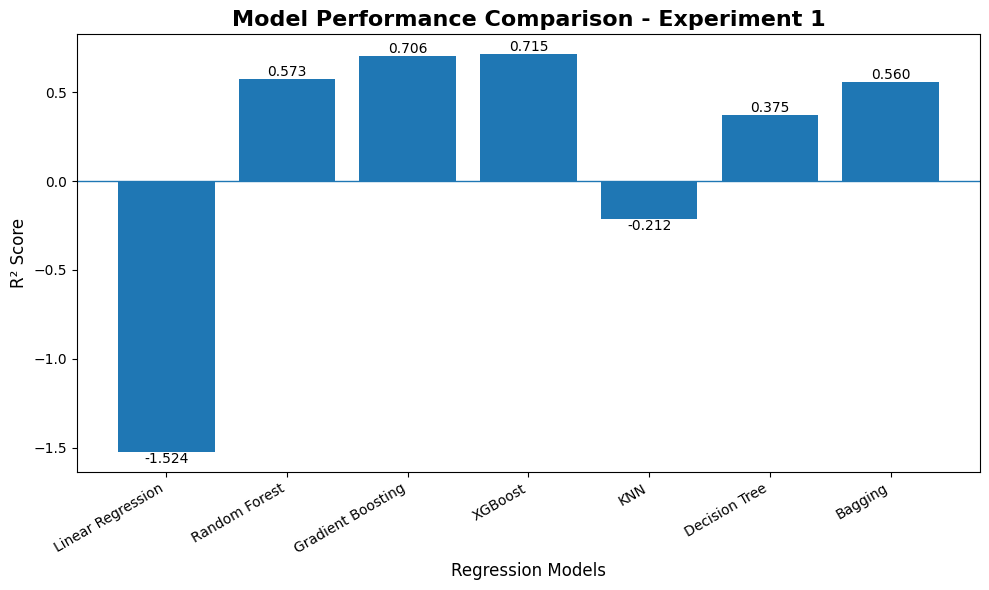

In [35]:
import matplotlib.pyplot as plt

# Model names
models = [
    'Linear Regression',
    'Random Forest',
    'Gradient Boosting',
    'XGBoost',
    'KNN',
    'Decision Tree',
    'Bagging'
]

# R² scores from Experiment 1
r2_scores = [
    r2_lr,
    r2_rf,
    r2_gb,
    r2_xgb,
    r2_knn,
    r2_dt,
    r2_bag
]

# Create graph
plt.figure(figsize=(10, 6))

bars = plt.bar(models, r2_scores)

plt.axhline(y=0, linewidth=1)

plt.title('Model Performance Comparison - Experiment 1',
          fontsize=16, fontweight='bold')

plt.xlabel('Regression Models', fontsize=12)
plt.ylabel('R² Score', fontsize=12)

plt.xticks(rotation=30, ha='right')

# Add values above bars
for bar, value in zip(bars, r2_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.3f}',
        ha='center',
        va='bottom' if value >= 0 else 'top',
        fontsize=10
    )

plt.tight_layout()

# Save for presentation
plt.savefig(
    'model_performance_experiment1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

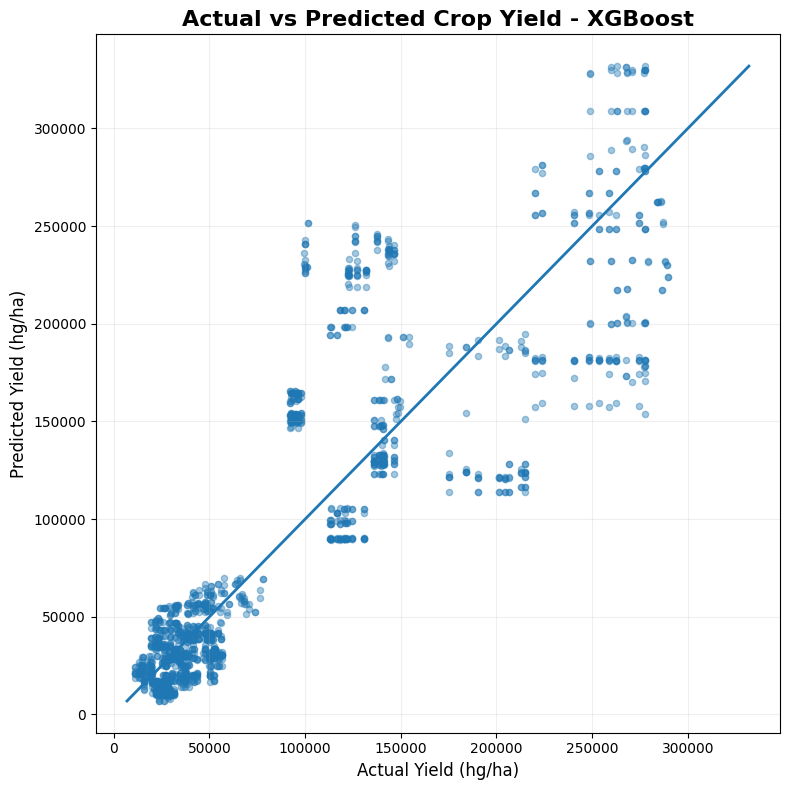

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Actual and predicted values
actual = np.array(y_test)
predicted = np.array(y_pred_xgb)

plt.figure(figsize=(8, 8))

# Scatter plot
plt.scatter(
    actual,
    predicted,
    alpha=0.4,
    s=20
)

# Perfect prediction line
min_value = min(actual.min(), predicted.min())
max_value = max(actual.max(), predicted.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linewidth=2
)

plt.title(
    'Actual vs Predicted Crop Yield - XGBoost',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Actual Yield (hg/ha)', fontsize=12)
plt.ylabel('Predicted Yield (hg/ha)', fontsize=12)

plt.grid(alpha=0.2)

plt.tight_layout()

# Save for presentation
plt.savefig(
    'actual_vs_predicted_xgboost.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

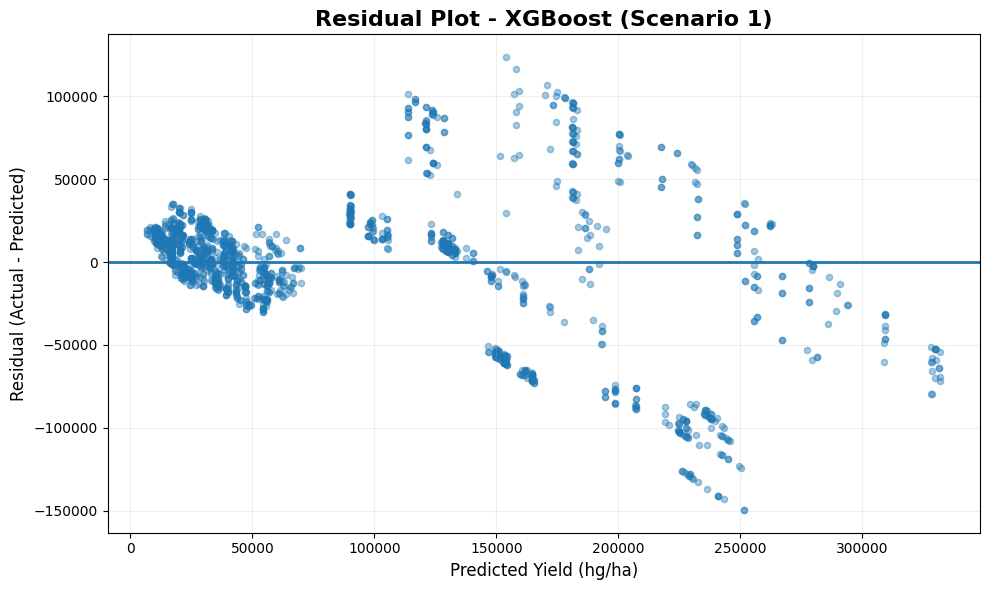

In [37]:
import matplotlib.pyplot as plt
import numpy as np

actual = np.array(y_test)
predicted = np.array(y_pred_xgb)

# Residual = Actual - Predicted
residuals = actual - predicted

plt.figure(figsize=(10, 6))

plt.scatter(
    predicted,
    residuals,
    alpha=0.4,
    s=20
)

# Zero-error reference line
plt.axhline(
    y=0,
    linewidth=2
)

plt.title(
    'Residual Plot - XGBoost (Scenario 1)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Predicted Yield (hg/ha)', fontsize=12)
plt.ylabel('Residual (Actual - Predicted)', fontsize=12)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    'residual_plot_xgboost_scenario1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

,Area,MAE,MAPE
0,Argentina,30066.287381,30.945211
1,Brazil,25046.088335,38.146525
2,Mexico,34336.266934,37.021135


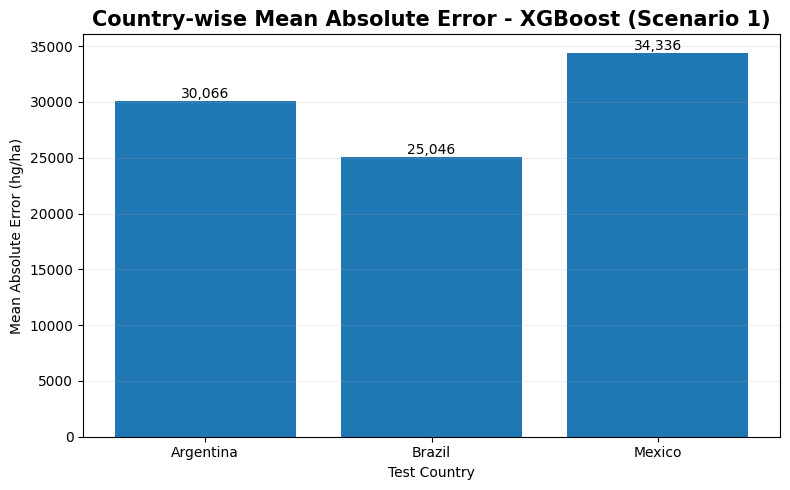

In [38]:
import matplotlib.pyplot as plt

country_error = (
    error_df
    .groupby('Area')
    .agg(
        MAE=('Absolute_Error', 'mean'),
        MAPE=('Percentage_Error', 'mean')
    )
    .reset_index()
)

display(country_error)

# MAE graph
plt.figure(figsize=(8, 5))

bars = plt.bar(
    country_error['Area'],
    country_error['MAE']
)

plt.title(
    'Country-wise Mean Absolute Error - XGBoost (Scenario 1)',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Test Country')
plt.ylabel('Mean Absolute Error (hg/ha)')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, country_error['MAE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()

plt.savefig(
    'country_wise_mae_scenario1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

,Item,MAE,MAPE
8,Yams,61367.848643,64.947444
0,Cassava,56577.652612,45.591171
2,Potatoes,50555.313740,19.406701
6,Sweet potatoes,46312.580192,30.055056
1,Maize,13768.713862,34.884582
4,Sorghum,13663.525887,50.212048
7,Wheat,12568.896629,32.830594
5,Soybeans,11371.367503,50.600002
3,"Rice, paddy",8662.811095,18.636996


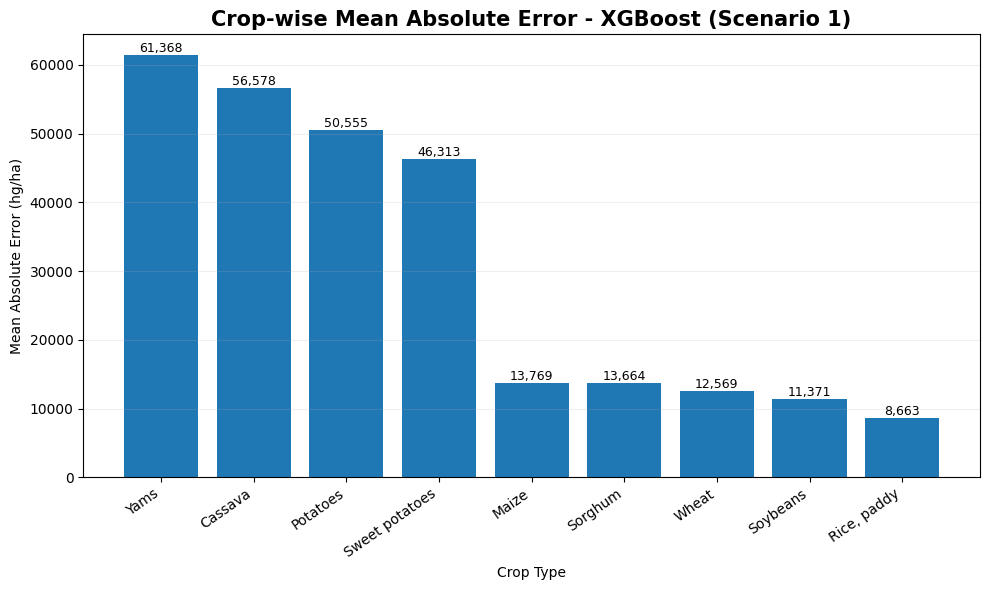

In [39]:
import matplotlib.pyplot as plt

crop_error = (
    error_df
    .groupby('Item')
    .agg(
        MAE=('Absolute_Error', 'mean'),
        MAPE=('Percentage_Error', 'mean')
    )
    .reset_index()
    .sort_values('MAE', ascending=False)
)

display(crop_error)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    crop_error['Item'],
    crop_error['MAE']
)

plt.title(
    'Crop-wise Mean Absolute Error - XGBoost (Scenario 1)',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Crop Type')
plt.ylabel('Mean Absolute Error (hg/ha)')

plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, crop_error['MAE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'crop_wise_mae_scenario1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

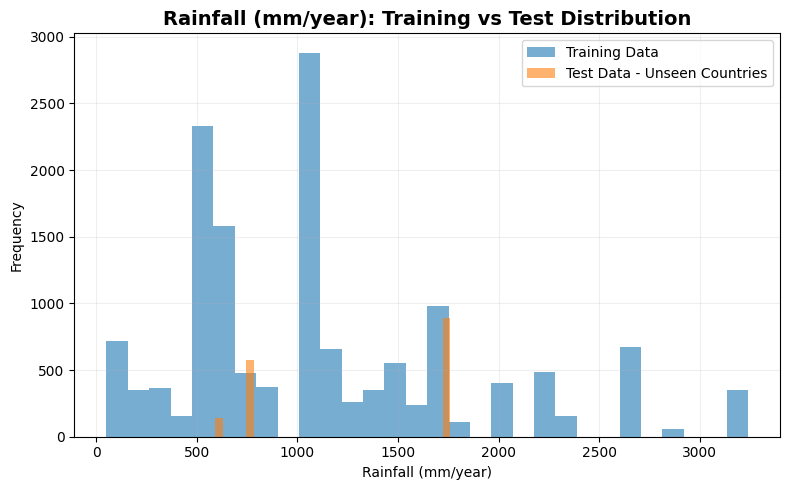

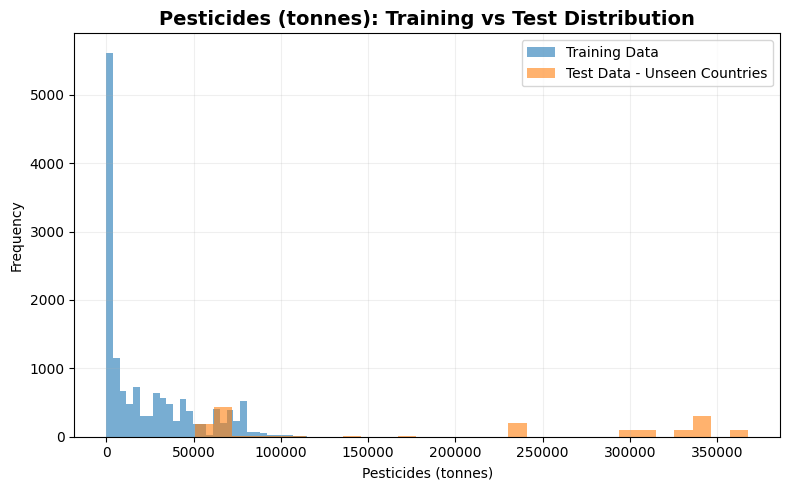

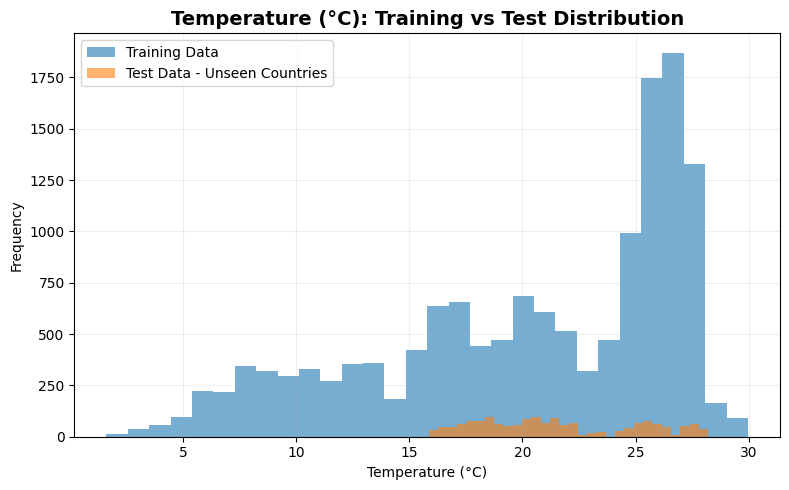

In [40]:
import matplotlib.pyplot as plt

features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

feature_names = [
    'Rainfall (mm/year)',
    'Pesticides (tonnes)',
    'Temperature (°C)'
]

for feature, name in zip(features, feature_names):

    plt.figure(figsize=(8, 5))

    plt.hist(
        train_data[feature].dropna(),
        bins=30,
        alpha=0.6,
        label='Training Data'
    )

    plt.hist(
        test_data[feature].dropna(),
        bins=30,
        alpha=0.6,
        label='Test Data - Unseen Countries'
    )

    plt.title(
        f'{name}: Training vs Test Distribution',
        fontsize=14,
        fontweight='bold'
    )

    plt.xlabel(name)
    plt.ylabel('Frequency')

    plt.legend()
    plt.grid(alpha=0.2)

    plt.tight_layout()

    plt.savefig(
        f'{feature}_distribution_scenario1.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

In [41]:
features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

feature_names = [
    'Rainfall',
    'Pesticides',
    'Temperature'
]

train_means = train_data[features].mean()
test_means = test_data[features].mean()

comparison = pd.DataFrame({
    'Feature': feature_names,
    'Training Mean': train_means.values,
    'Test Mean': test_means.values
})

comparison['Difference'] = (
    comparison['Test Mean'] - comparison['Training Mean']
)

comparison['Difference (%)'] = (
    comparison['Difference'] /
    comparison['Training Mean']
) * 100

display(comparison)

,Feature,Training Mean,Test Mean,Difference,Difference (%)
0,Rainfall,1124.737139,1297.804469,173.067330,15.387358
1,Pesticides,22600.700019,203949.939938,181349.239919,802.405411
2,Temperature,20.329521,21.534910,1.205389,5.929252


In [42]:
scenario1_summary = pd.DataFrame({
    'Analysis': [
        'Overall Model Performance',
        'Prediction Behavior',
        'Country-wise Error',
        'Crop-wise Error',
        'Feature Distribution',
        'Generalization Condition'
    ],
    'Finding': [
        'XGBoost achieved the highest R² among the tested models in Scenario 1.',
        'Both overprediction and underprediction are present, with visible residual patterns.',
        'Prediction errors vary across the unseen countries.',
        'Prediction errors vary across crop types, with some crops showing substantially larger errors.',
        'Test features show distribution differences compared with training data.',
        'The model was tested on both unseen countries and later years.'
    ]
})

display(scenario1_summary)

,Analysis,Finding
0,Overall Model Performance,XGBoost achieved the highest R² among the test...
1,Prediction Behavior,Both overprediction and underprediction are pr...
2,Country-wise Error,Prediction errors vary across the unseen count...
3,Crop-wise Error,"Prediction errors vary across crop types, with..."
4,Feature Distribution,Test features show distribution differences co...
5,Generalization Condition,The model was tested on both unseen countries ...


In [43]:
# Scenario 2: Same Countries + Different Years

train_data_s2 = df[
    df['Year'].between(1990, 2004)
].copy()

test_data_s2 = df[
    df['Year'].between(2005, 2013)
].copy()

print("Training data:", train_data_s2.shape)
print("Testing data:", test_data_s2.shape)

print("\nTraining years:",
      train_data_s2['Year'].min(),
      "to",
      train_data_s2['Year'].max())

print("Testing years:",
      test_data_s2['Year'].min(),
      "to",
      test_data_s2['Year'].max())

print("\nTraining countries:",
      train_data_s2['Area'].nunique())

print("Testing countries:",
      test_data_s2['Area'].nunique())

Training data: (17027, 8)
Testing data: (11215, 8)

Training years: 1990 to 2004
Testing years: 2005 to 2013

Training countries: 99
Testing countries: 101


In [44]:
train_countries_s2 = set(train_data_s2['Area'].unique())
test_countries_s2 = set(test_data_s2['Area'].unique())

new_countries = test_countries_s2 - train_countries_s2

print("Countries only in test data:")
print(new_countries)

Countries only in test data:
{'Montenegro', 'Sudan'}


In [45]:
# Countries available during the training period
common_countries_s2 = train_data_s2['Area'].unique()

# Keep only those same countries in the test period
test_data_s2 = test_data_s2[
    test_data_s2['Area'].isin(common_countries_s2)
].copy()

print("Training countries:", train_data_s2['Area'].nunique())
print("Testing countries:", test_data_s2['Area'].nunique())

print("\nCountry overlap:",
      len(
          set(train_data_s2['Area'].unique())
          &
          set(test_data_s2['Area'].unique())
      ))

print("\nTraining years:",
      train_data_s2['Year'].min(),
      "to",
      train_data_s2['Year'].max())

print("Testing years:",
      test_data_s2['Year'].min(),
      "to",
      test_data_s2['Year'].max())

Training countries: 99
Testing countries: 99

Country overlap: 99

Training years: 1990 to 2004
Testing years: 2005 to 2013


In [46]:
# Remove unnecessary index column
train_data_s2 = train_data_s2.drop(
    columns=['Unnamed: 0'],
    errors='ignore'
)

test_data_s2 = test_data_s2.drop(
    columns=['Unnamed: 0'],
    errors='ignore'
)

# Features
features_s2 = [
    'Item',
    'Year',
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

X_train_s2 = train_data_s2[features_s2].copy()
X_test_s2 = test_data_s2[features_s2].copy()

# Target
y_train_s2 = train_data_s2['hg/ha_yield']
y_test_s2 = test_data_s2['hg/ha_yield']

print("X_train:", X_train_s2.shape)
print("X_test:", X_test_s2.shape)

print("y_train:", y_train_s2.shape)
print("y_test:", y_test_s2.shape)

print("\nFeatures:")
print(X_train_s2.columns.tolist())

X_train: (17027, 5)
X_test: (11163, 5)
y_train: (17027,)
y_test: (11163,)

Features:
['Item', 'Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


In [47]:
from sklearn.preprocessing import OneHotEncoder

encoder_s2 = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit ONLY on training crops
train_item_encoded_s2 = encoder_s2.fit_transform(
    X_train_s2[['Item']]
)

# Transform test crops using the same encoder
test_item_encoded_s2 = encoder_s2.transform(
    X_test_s2[['Item']]
)

# Get encoded column names
encoded_columns_s2 = encoder_s2.get_feature_names_out(['Item'])

train_item_df_s2 = pd.DataFrame(
    train_item_encoded_s2,
    columns=encoded_columns_s2,
    index=X_train_s2.index
)

test_item_df_s2 = pd.DataFrame(
    test_item_encoded_s2,
    columns=encoded_columns_s2,
    index=X_test_s2.index
)

# Remove original Item column
X_train_s2 = X_train_s2.drop(columns=['Item'])
X_test_s2 = X_test_s2.drop(columns=['Item'])

# Add encoded crop columns
X_train_s2 = pd.concat(
    [X_train_s2, train_item_df_s2],
    axis=1
)

X_test_s2 = pd.concat(
    [X_test_s2, test_item_df_s2],
    axis=1
)

print("X_train shape:", X_train_s2.shape)
print("X_test shape:", X_test_s2.shape)

print("\nSame columns:",
      list(X_train_s2.columns) == list(X_test_s2.columns))

print("Missing values in X_train:",
      X_train_s2.isnull().sum().sum())

print("Missing values in X_test:",
      X_test_s2.isnull().sum().sum())

print("All features numeric:",
      X_train_s2.dtypes.apply(lambda x: np.issubdtype(x, np.number)).all())

X_train shape: (17027, 14)
X_test shape: (11163, 14)

Same columns: True
Missing values in X_train: 0
Missing values in X_test: 0
All features numeric: True


In [48]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    BaggingRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

models_s2 = {
    'Linear Regression': LinearRegression(),

    'Random Forest': RandomForestRegressor(
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    'XGBoost': XGBRegressor(
        random_state=42
    ),

    'KNN': KNeighborsRegressor(
        n_neighbors=5
    ),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Bagging': BaggingRegressor(
        n_estimators=150,
        random_state=42
    )
}

print("Total models:", len(models_s2))
print("\nModels:")
for name in models_s2:
    print("-", name)

Total models: 7

Models:
- Linear Regression
- Random Forest
- Gradient Boosting
- XGBoost
- KNN
- Decision Tree
- Bagging


In [49]:
# Train Linear Regression
lr_s2 = LinearRegression()

lr_s2.fit(X_train_s2, y_train_s2)

# Predictions
y_pred_lr_s2 = lr_s2.predict(X_test_s2)

print("Linear Regression training completed.")
print("Number of predictions:", len(y_pred_lr_s2))

Linear Regression training completed.
Number of predictions: 11163


In [50]:
# Train Random Forest
rf_s2 = RandomForestRegressor(
    random_state=42
)

rf_s2.fit(X_train_s2, y_train_s2)

# Predictions
y_pred_rf_s2 = rf_s2.predict(X_test_s2)

print("Random Forest training completed.")
print("Number of predictions:", len(y_pred_rf_s2))

Random Forest training completed.
Number of predictions: 11163


In [51]:
# Train Gradient Boosting
gb_s2 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_s2.fit(X_train_s2, y_train_s2)

# Predictions
y_pred_gb_s2 = gb_s2.predict(X_test_s2)

print("Gradient Boosting training completed.")
print("Number of predictions:", len(y_pred_gb_s2))

Gradient Boosting training completed.
Number of predictions: 11163


In [52]:
# Train XGBoost
xgb_s2 = XGBRegressor(
    random_state=42
)

xgb_s2.fit(X_train_s2, y_train_s2)

# Predictions
y_pred_xgb_s2 = xgb_s2.predict(X_test_s2)

print("XGBoost training completed.")
print("Number of predictions:", len(y_pred_xgb_s2))

XGBoost training completed.
Number of predictions: 11163


In [53]:
# Train KNN
knn_s2 = KNeighborsRegressor(
    n_neighbors=5
)

knn_s2.fit(X_train_s2, y_train_s2)

# Predictions
y_pred_knn_s2 = knn_s2.predict(X_test_s2)

print("KNN training completed.")
print("Number of predictions:", len(y_pred_knn_s2))

KNN training completed.
Number of predictions: 11163


In [54]:
# Train Decision Tree
dt_s2 = DecisionTreeRegressor(
    random_state=42
)

dt_s2.fit(X_train_s2, y_train_s2)

# Predictions
y_pred_dt_s2 = dt_s2.predict(X_test_s2)

print("Decision Tree training completed.")
print("Number of predictions:", len(y_pred_dt_s2))

Decision Tree training completed.
Number of predictions: 11163


In [55]:
# Train Bagging Regressor
bag_s2 = BaggingRegressor(
    n_estimators=150,
    random_state=42
)

bag_s2.fit(X_train_s2, y_train_s2)

# Predictions
y_pred_bag_s2 = bag_s2.predict(X_test_s2)

print("Bagging Regressor training completed.")
print("Number of predictions:", len(y_pred_bag_s2))

Bagging Regressor training completed.
Number of predictions: 11163


In [56]:
# Choose the test record you want to examine

selected_country = 'Brazil'
selected_crop = 'Maize'
selected_year = 2009

# Find the selected record
selected_data = test_data_s2[
    (test_data_s2['Area'] == selected_country) &
    (test_data_s2['Item'] == selected_crop) &
    (test_data_s2['Year'] == selected_year)
].copy()

if selected_data.empty:
    print("No matching record found.")
else:
    print("Selected Test Record:")

    display(
        selected_data[
            [
                'Area',
                'Item',
                'Year',
                'average_rain_fall_mm_per_year',
                'pesticides_tonnes',
                'avg_temp',
                'hg/ha_yield'
            ]
        ]
    )

Selected Test Record:


,Area,Item,Year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,hg/ha_yield
4335,Brazil,Maize,2009,1761.0,335742.0,22.25,37145
4336,Brazil,Maize,2009,1761.0,335742.0,20.78,37145
4337,Brazil,Maize,2009,1761.0,335742.0,18.38,37145
4338,Brazil,Maize,2009,1761.0,335742.0,18.38,37145
4339,Brazil,Maize,2009,1761.0,335742.0,27.39,37145
4340,Brazil,Maize,2009,1761.0,335742.0,20.78,37145
4341,Brazil,Maize,2009,1761.0,335742.0,27.39,37145
4342,Brazil,Maize,2009,1761.0,335742.0,18.84,37145
4343,Brazil,Maize,2009,1761.0,335742.0,26.30,37145
4344,Brazil,Maize,2009,1761.0,335742.0,24.98,37145


In [57]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Store all model predictions
predictions_s2 = {
    'Linear Regression': y_pred_lr_s2,
    'Random Forest': y_pred_rf_s2,
    'Gradient Boosting': y_pred_gb_s2,
    'XGBoost': y_pred_xgb_s2,
    'KNN': y_pred_knn_s2,
    'Decision Tree': y_pred_dt_s2,
    'Bagging': y_pred_bag_s2
}

results_s2 = []

for model_name, predictions in predictions_s2.items():

    mae = mean_absolute_error(
        y_test_s2,
        predictions
    )

    mse = mean_squared_error(
        y_test_s2,
        predictions
    )

    rmse = np.sqrt(mse)

    # Avoid division by zero in MAPE
    non_zero = y_test_s2 != 0

    mape = np.mean(
        np.abs(
            (y_test_s2[non_zero] - predictions[non_zero])
            / y_test_s2[non_zero]
        )
    ) * 100

    r2 = r2_score(
        y_test_s2,
        predictions
    )

    results_s2.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape,
        'R²': r2
    })

results_s2 = pd.DataFrame(results_s2)

display(results_s2)

,Model,MAE,MSE,RMSE,MAPE,R²
0,Linear Regression,37659.108881,3.414813e+09,58436.400744,91.501034,0.604122
1,Random Forest,13765.053562,8.454614e+08,29076.819590,21.208509,0.901986
2,Gradient Boosting,25325.939308,1.828357e+09,42759.290925,49.546271,0.788039
3,XGBoost,15288.160156,9.135677e+08,30225.283191,27.330826,0.894090
4,KNN,60470.332402,7.935143e+09,89079.418701,184.204310,0.080082
5,Decision Tree,15087.500672,1.052193e+09,32437.518089,24.004012,0.878020
6,Bagging,13745.707499,8.460969e+08,29087.744349,21.161810,0.901912


In [58]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=results_s2)

https://docs.google.com/spreadsheets/d/1PwuiT7_0E4nK0Dfkdo3FpyTdJKARP71b9GLR8nozkUA/edit#gid=0


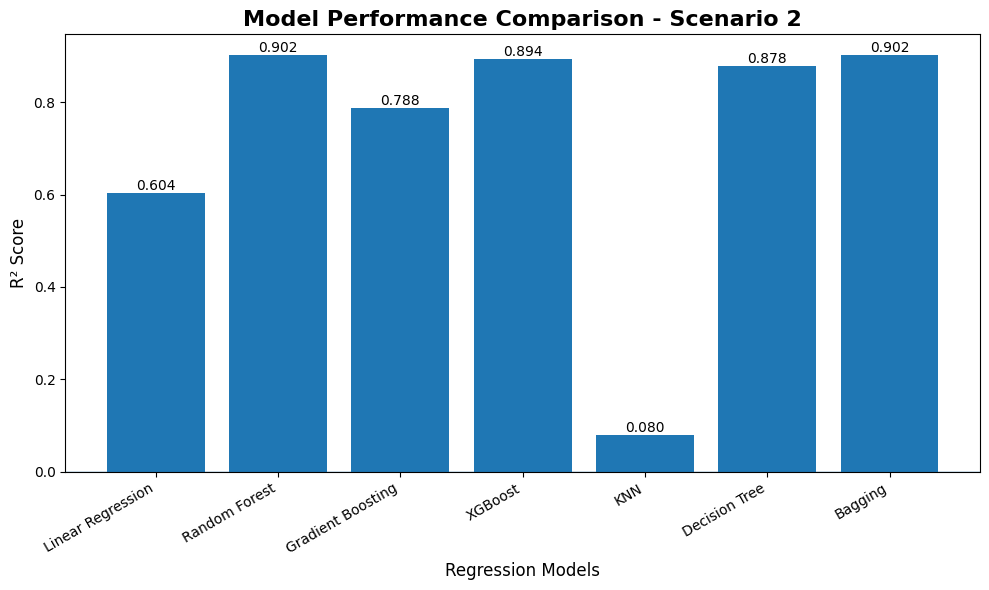

In [59]:
import matplotlib.pyplot as plt

models = results_s2['Model']
r2_scores = results_s2['R²']

plt.figure(figsize=(10, 6))

bars = plt.bar(models, r2_scores)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title(
    'Model Performance Comparison - Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel(
    'Regression Models',
    fontsize=12
)

plt.ylabel(
    'R² Score',
    fontsize=12
)

plt.xticks(
    rotation=30,
    ha='right'
)

for bar, value in zip(bars, r2_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.3f}',
        ha='center',
        va='bottom' if value >= 0 else 'top',
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    'model_performance_scenario2_r2.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

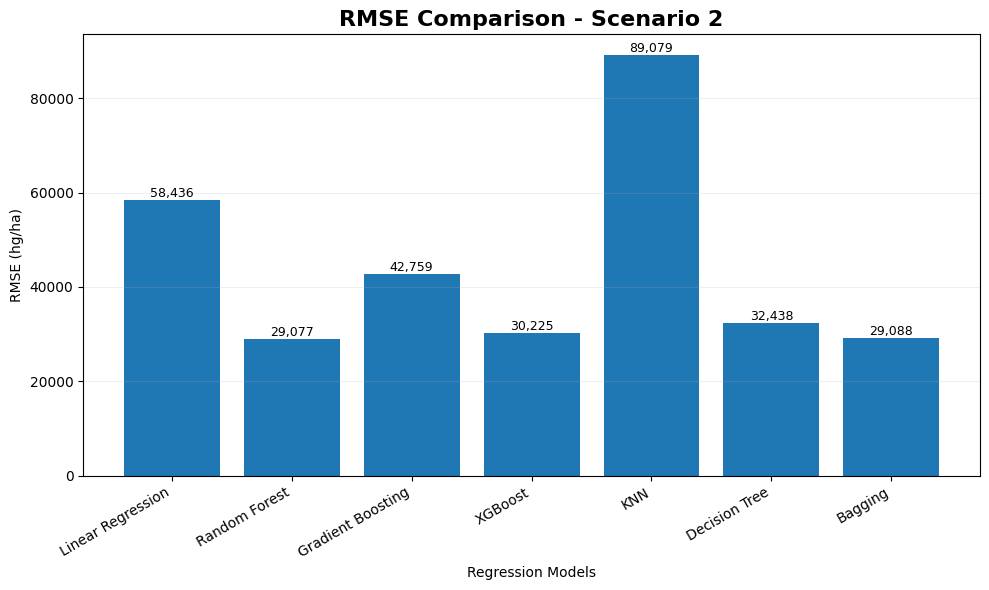

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s2['Model'],
    results_s2['RMSE']
)

plt.title(
    'RMSE Comparison - Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('RMSE (hg/ha)')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, results_s2['RMSE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario2_rmse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

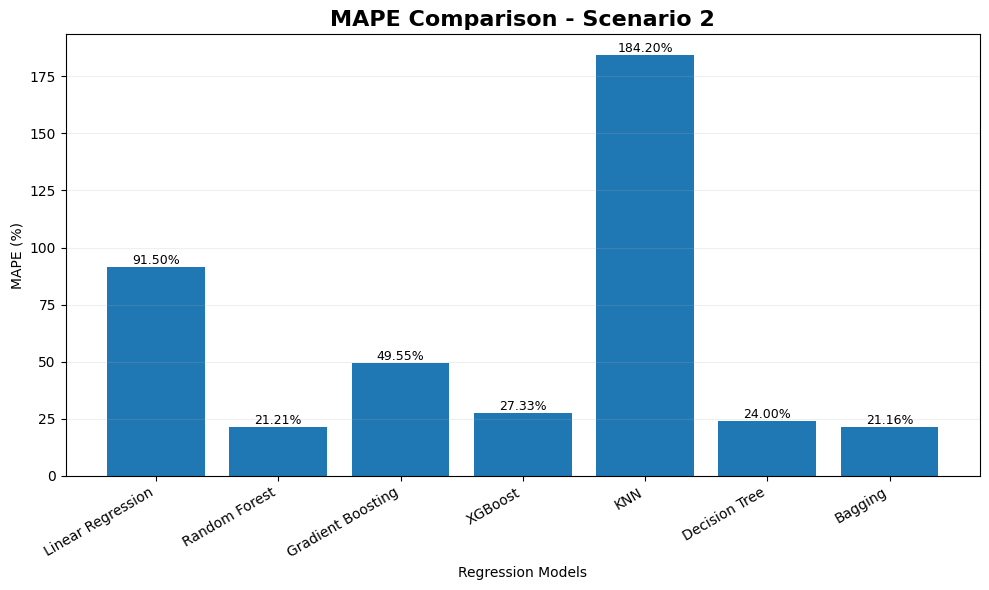

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s2['Model'],
    results_s2['MAPE']
)

plt.title(
    'MAPE Comparison - Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MAPE (%)')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, results_s2['MAPE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.2f}%',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario2_mape_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

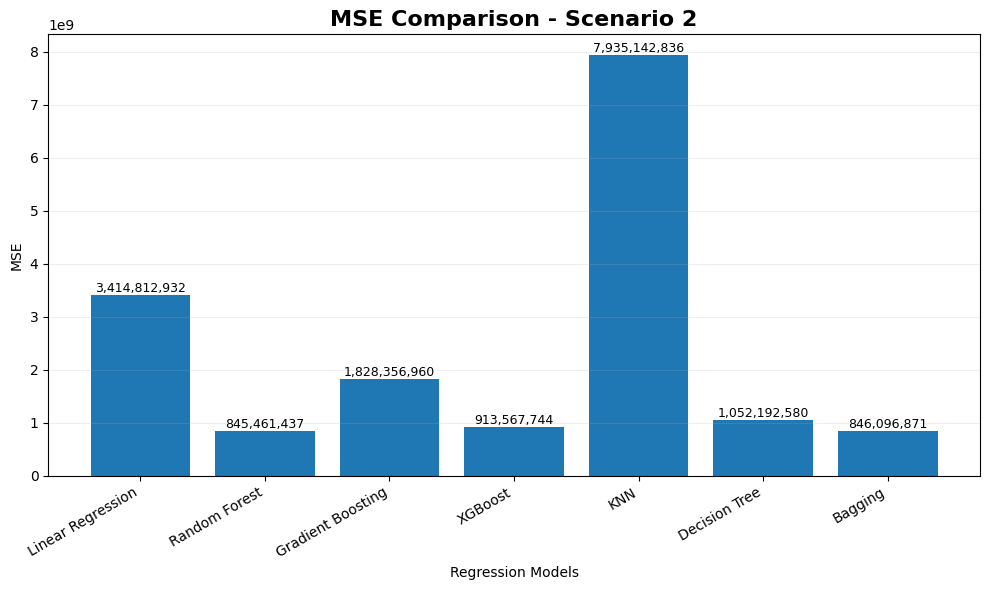

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s2['Model'],
    results_s2['MSE']
)

plt.title(
    'MSE Comparison - Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MSE')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, results_s2['MSE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario2_mse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

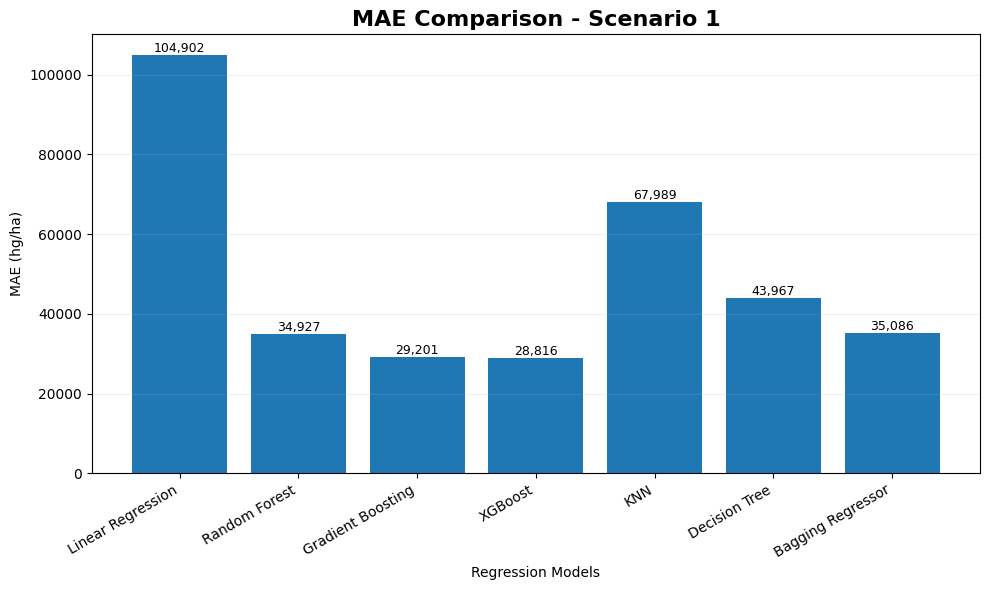

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results['Model'],
    results['MAE']
)

plt.title(
    'MAE Comparison - Scenario 1',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MAE (hg/ha)')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, results['MAE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario1_mae_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

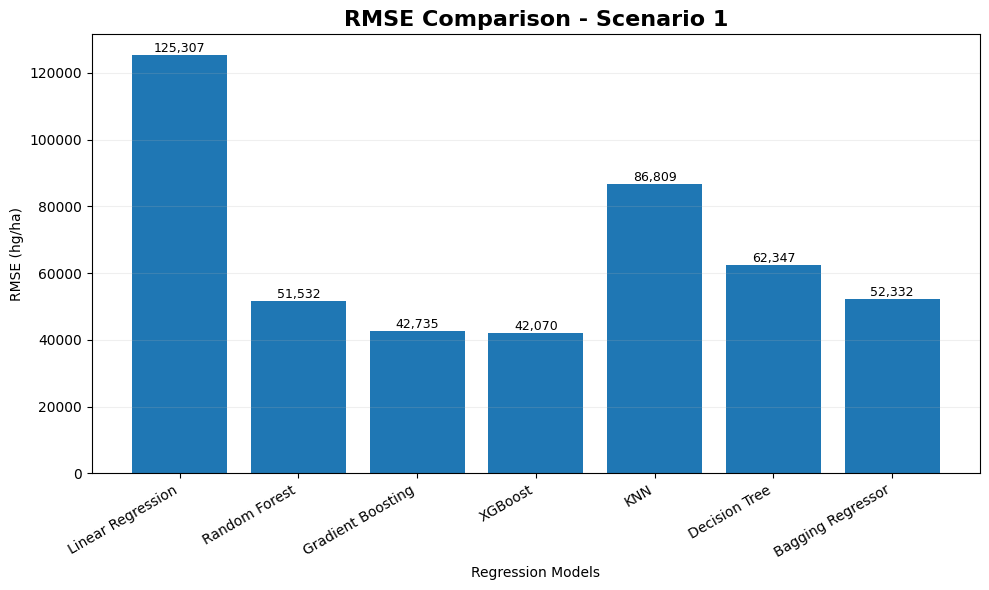

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results['Model'],
    results['RMSE']
)

plt.title(
    'RMSE Comparison - Scenario 1',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('RMSE (hg/ha)')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, results['RMSE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario1_rmse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

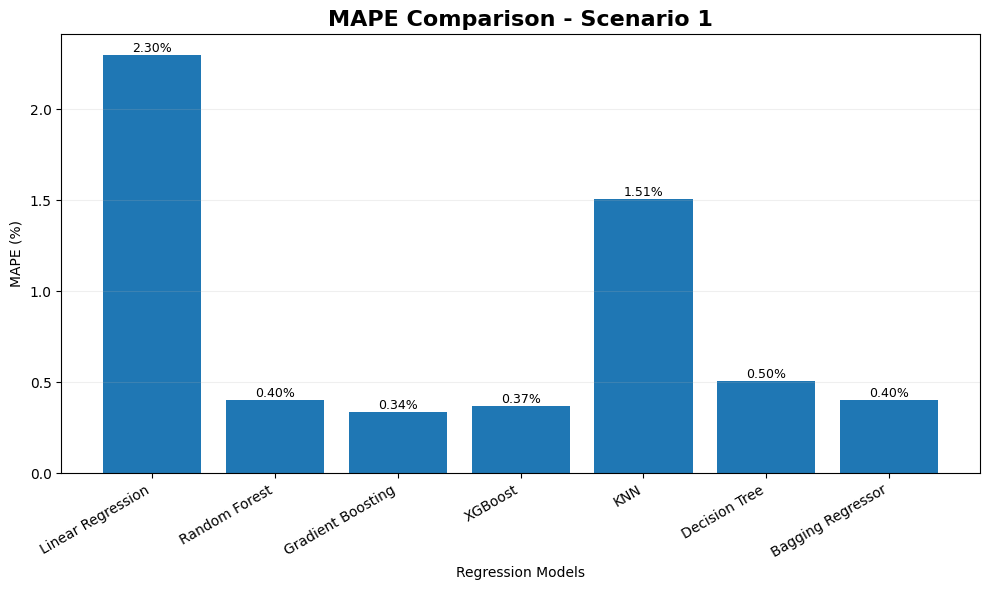

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results['Model'],
    results['MAPE']
)

plt.title(
    'MAPE Comparison - Scenario 1',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MAPE (%)')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, results['MAPE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.2f}%',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario1_mape_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

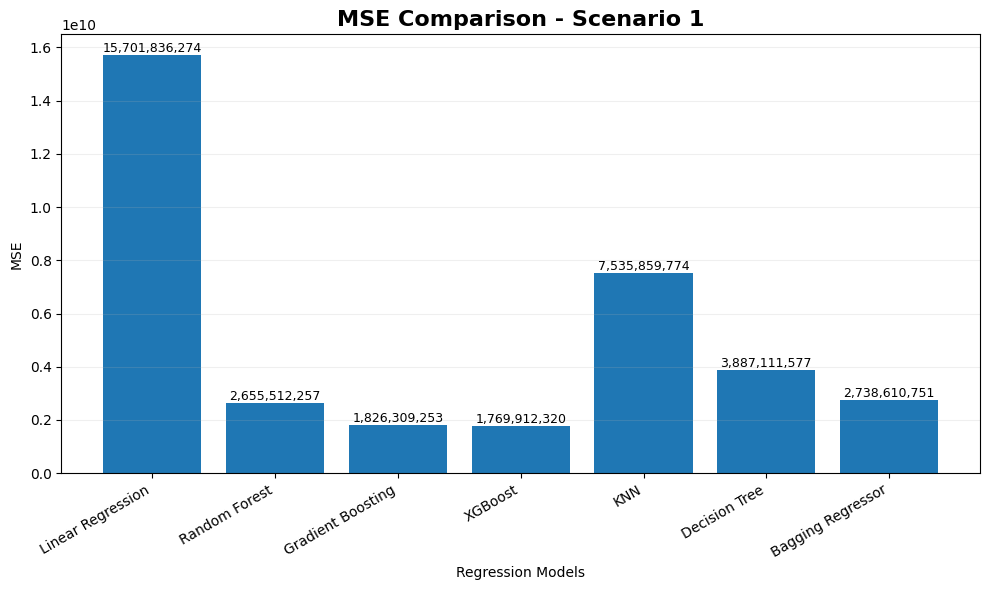

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results['Model'],
    results['MSE']
)

plt.title(
    'MSE Comparison - Scenario 1',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MSE')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, results['MSE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario1_mse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

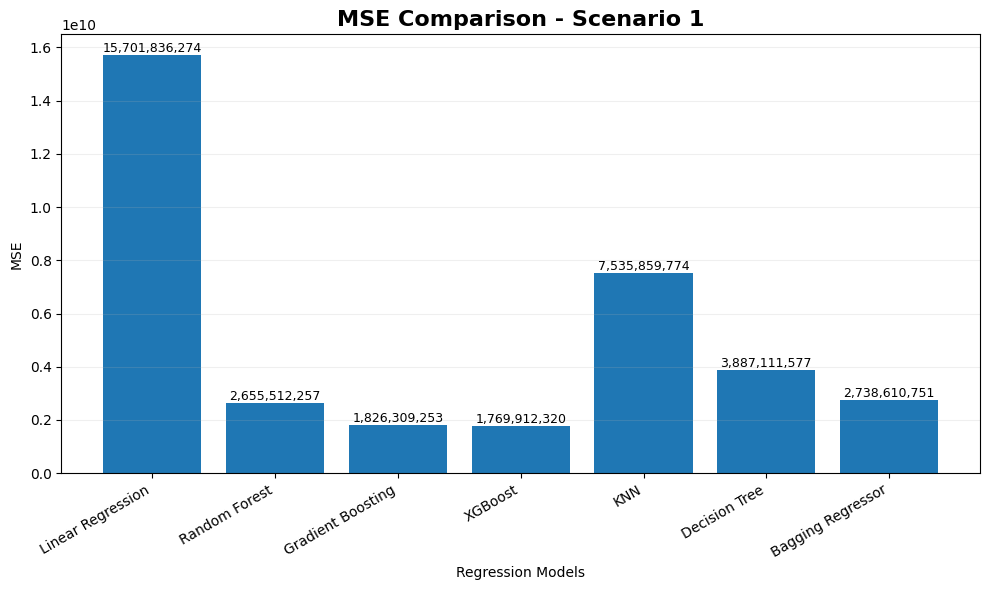

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results['Model'],
    results['MSE']
)

plt.title(
    'MSE Comparison - Scenario 1',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MSE')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.2)

for bar, value in zip(bars, results['MSE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario1_mse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [68]:
features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

feature_names = [
    'Rainfall',
    'Pesticides',
    'Temperature'
]

train_means_s2 = train_data_s2[features].mean()
test_means_s2 = test_data_s2[features].mean()

comparison_s2 = pd.DataFrame({
    'Feature': feature_names,
    'Training Mean (1990–2004)': train_means_s2.values,
    'Test Mean (2005–2013)': test_means_s2.values
})

comparison_s2['Difference'] = (
    comparison_s2['Test Mean (2005–2013)'] -
    comparison_s2['Training Mean (1990–2004)']
)

comparison_s2['Difference (%)'] = (
    comparison_s2['Difference'] /
    comparison_s2['Training Mean (1990–2004)']
) * 100

display(comparison_s2)

,Feature,Training Mean (1990–2004),Test Mean (2005–2013),Difference,Difference (%)
0,Rainfall,1150.208845,1147.837768,-2.371077,-0.206143
1,Pesticides,30568.555883,47170.584870,16602.028987,54.310806
2,Temperature,20.480297,20.637227,0.156929,0.766246


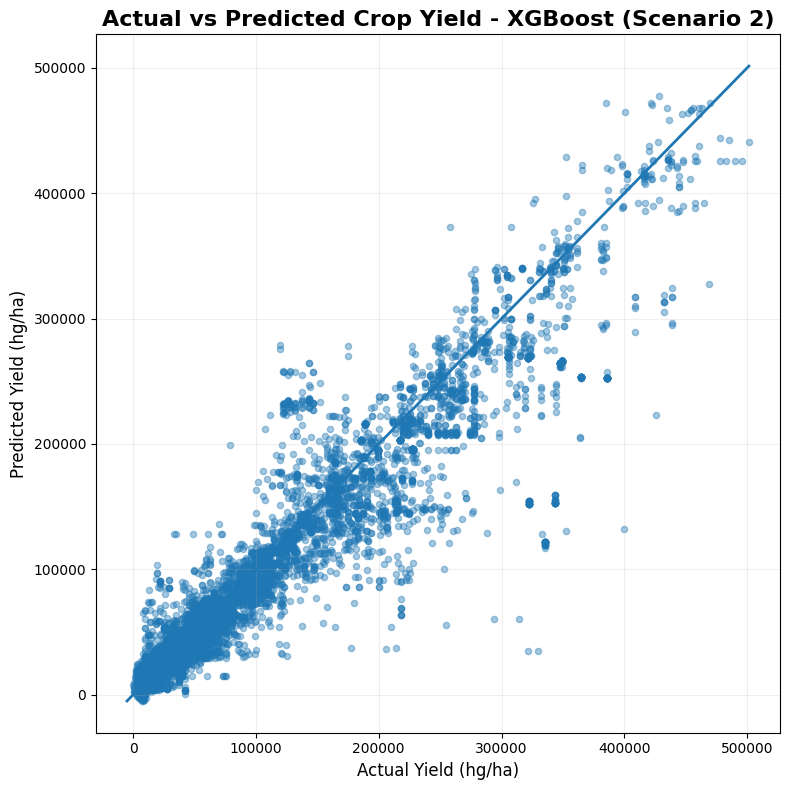

In [69]:
import matplotlib.pyplot as plt
import numpy as np

actual = np.array(y_test_s2)
predicted = np.array(y_pred_xgb_s2)

plt.figure(figsize=(8, 8))

plt.scatter(
    actual,
    predicted,
    alpha=0.4,
    s=20
)

min_value = min(actual.min(), predicted.min())
max_value = max(actual.max(), predicted.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linewidth=2
)

plt.title(
    'Actual vs Predicted Crop Yield - XGBoost (Scenario 2)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel(
    'Actual Yield (hg/ha)',
    fontsize=12
)

plt.ylabel(
    'Predicted Yield (hg/ha)',
    fontsize=12
)

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    'scenario2_actual_vs_predicted_xgboost.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

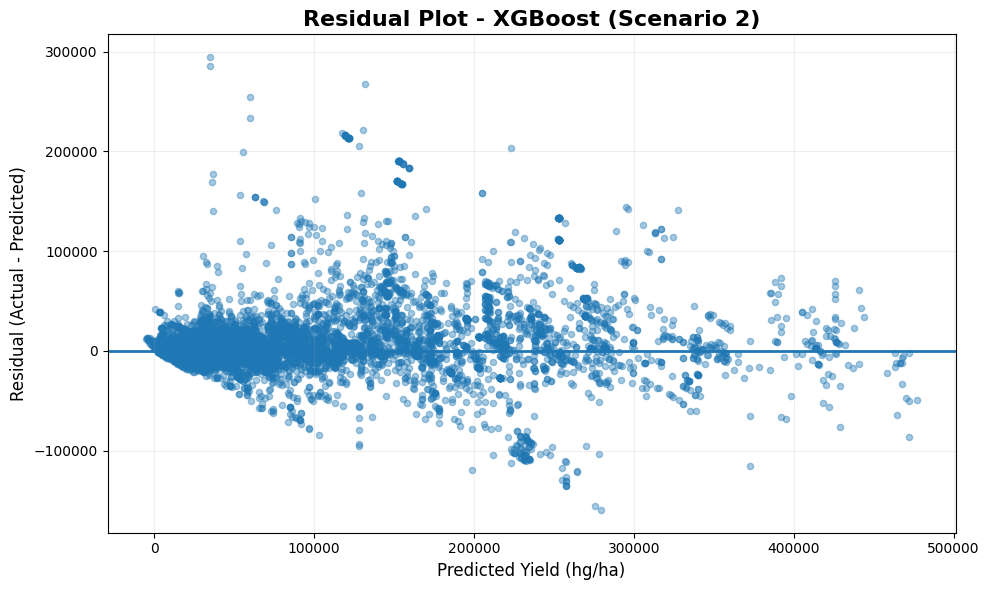

In [70]:
import matplotlib.pyplot as plt
import numpy as np

actual = np.array(y_test_s2)
predicted = np.array(y_pred_xgb_s2)

residuals = actual - predicted

plt.figure(figsize=(10, 6))

plt.scatter(
    predicted,
    residuals,
    alpha=0.4,
    s=20
)

plt.axhline(
    y=0,
    linewidth=2
)

plt.title(
    'Residual Plot - XGBoost (Scenario 2)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel(
    'Predicted Yield (hg/ha)',
    fontsize=12
)

plt.ylabel(
    'Residual (Actual - Predicted)',
    fontsize=12
)

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    'scenario2_residual_plot_xgboost.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [71]:
error_df_s2 = test_data_s2[
    ['Area', 'Item', 'Year']
].copy()

error_df_s2['Actual'] = y_test_s2.values
error_df_s2['Predicted'] = y_pred_xgb_s2

error_df_s2['Absolute_Error'] = (
    abs(
        error_df_s2['Actual'] -
        error_df_s2['Predicted']
    )
)

error_df_s2['Percentage_Error'] = (
    error_df_s2['Absolute_Error'] /
    error_df_s2['Actual'].replace(0, np.nan)
) * 100

country_error_s2 = (
    error_df_s2
    .groupby('Area')
    .agg(
        MAE=('Absolute_Error', 'mean'),
        MAPE=('Percentage_Error', 'mean')
    )
    .reset_index()
    .sort_values('MAE', ascending=False)
)

display(country_error_s2)

,Area,MAE,MAPE
9,Bahrain,45058.567708,27.101101
38,Guyana,43484.187934,40.714398
81,Senegal,42341.921785,48.272668
8,Bahamas,39605.323400,42.545040
68,New Zealand,37434.205946,26.903246
...,...,...,...
54,Libya,7034.444752,28.960023
22,Colombia,5917.993960,11.392614
13,Botswana,5859.518993,189.824434
73,Papua New Guinea,5079.971819,8.911044


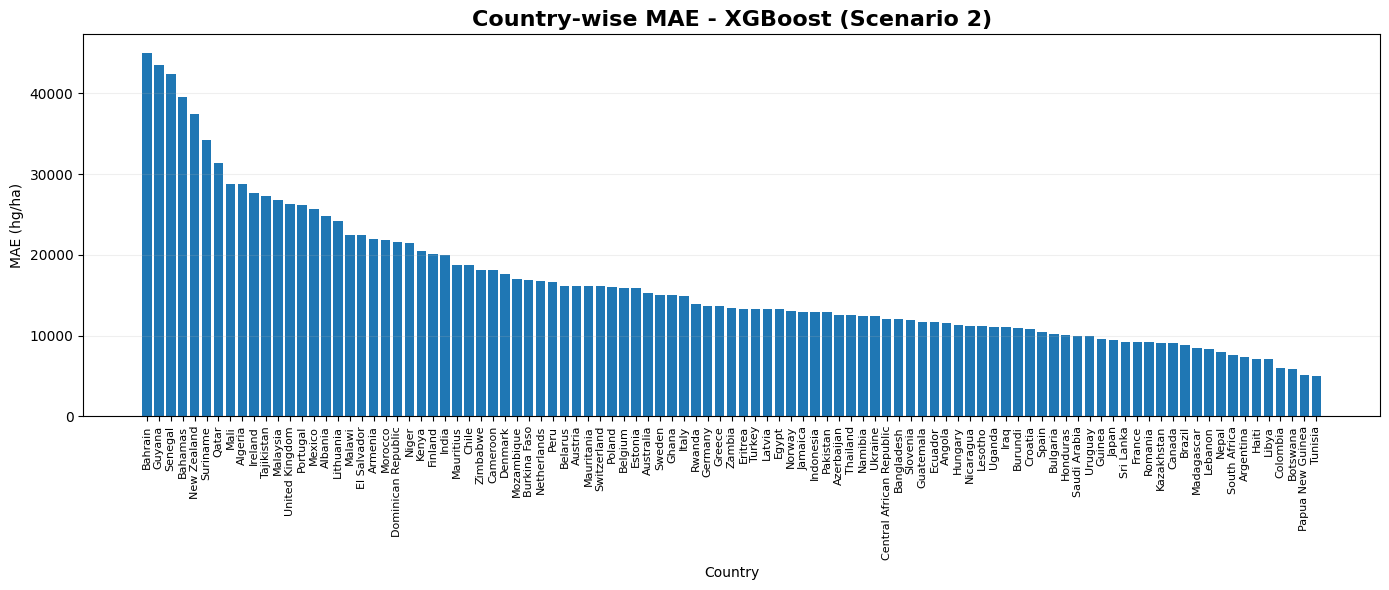

In [72]:
plt.figure(figsize=(14, 6))

plt.bar(
    country_error_s2['Area'],
    country_error_s2['MAE']
)

plt.title(
    'Country-wise MAE - XGBoost (Scenario 2)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Country')
plt.ylabel('MAE (hg/ha)')

plt.xticks(
    rotation=90,
    fontsize=8
)

plt.grid(
    axis='y',
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    'scenario2_country_wise_mae.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [73]:
crop_error_s2 = (
    error_df_s2
    .groupby('Item')
    .agg(
        MAE=('Absolute_Error', 'mean'),
        MAPE=('Percentage_Error', 'mean')
    )
    .reset_index()
    .sort_values('MAE', ascending=False)
)

display(crop_error_s2)

,Item,MAE,MAPE
0,Cassava,53353.840785,33.126266
3,Potatoes,27646.470162,17.457659
2,Plantains and others,27031.759925,32.556360
7,Sweet potatoes,21403.804770,21.720240
9,Yams,11606.952304,10.138141
1,Maize,10367.345507,33.958380
4,"Rice, paddy",7457.148006,20.133030
8,Wheat,5585.233744,24.005450
5,Sorghum,5172.865115,39.003927
6,Soybeans,4277.862257,37.066686


In [74]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=crop_error_s2)

https://docs.google.com/spreadsheets/d/1grgoANHqaOKvAIH612rHVmEgKL8BfbdDDUHHYHGc-Yc/edit#gid=0


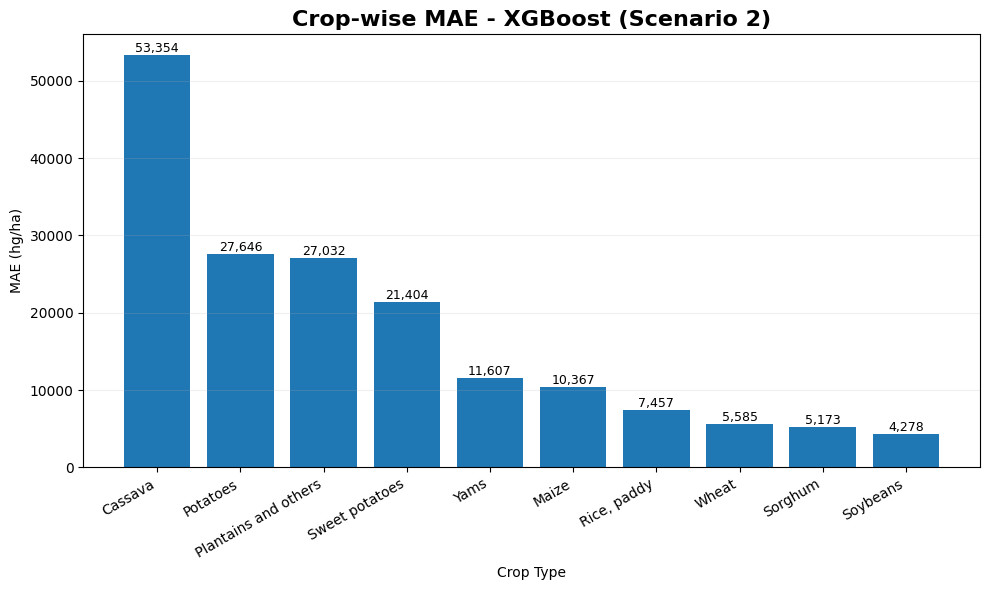

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    crop_error_s2['Item'],
    crop_error_s2['MAE']
)

plt.title(
    'Crop-wise MAE - XGBoost (Scenario 2)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Crop Type')
plt.ylabel('MAE (hg/ha)')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(bars, crop_error_s2['MAE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario2_crop_wise_mae.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

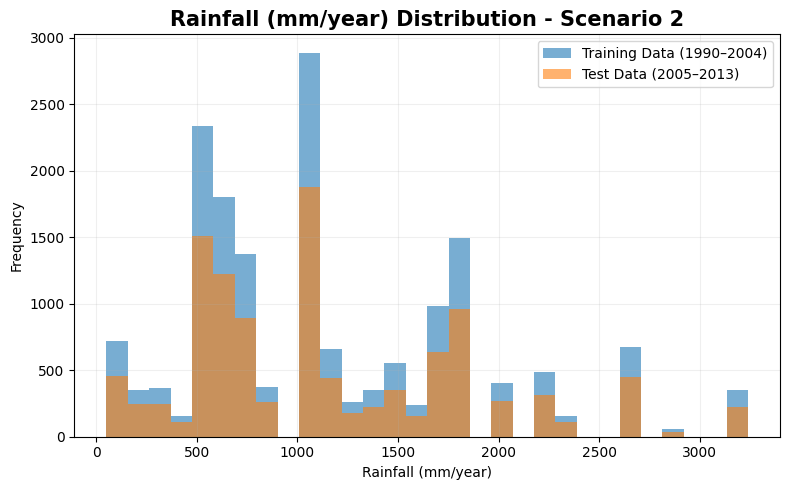

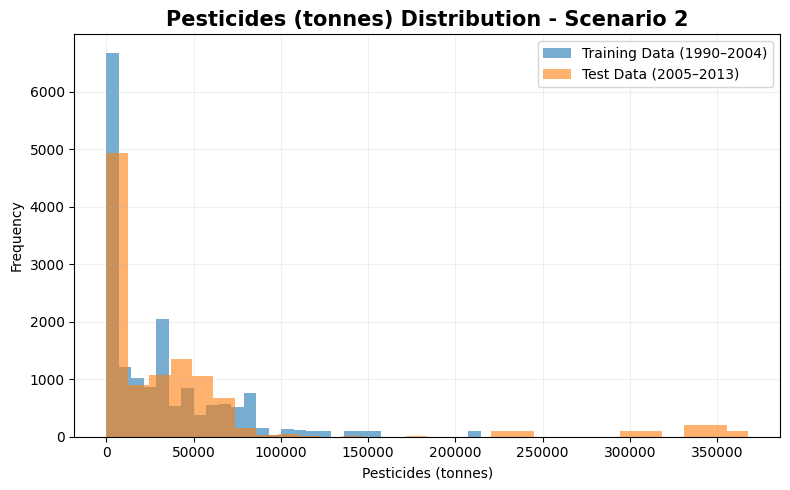

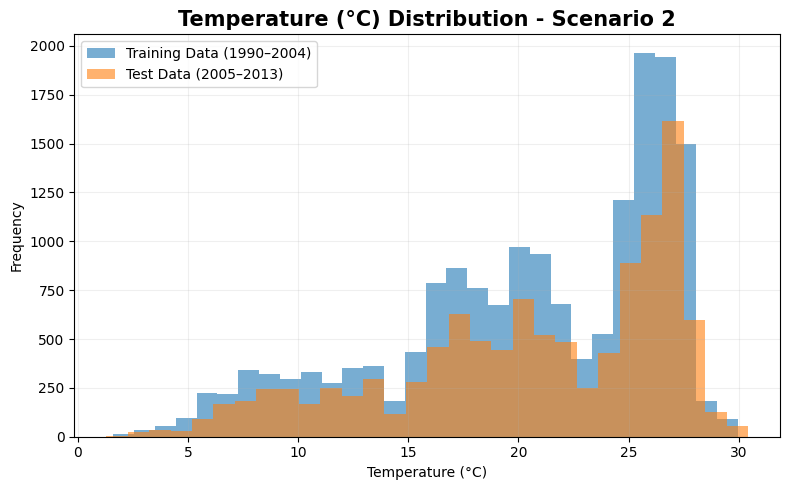

In [76]:
import matplotlib.pyplot as plt

features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

feature_names = [
    'Rainfall (mm/year)',
    'Pesticides (tonnes)',
    'Temperature (°C)'
]

for feature, name in zip(features, feature_names):

    plt.figure(figsize=(8, 5))

    plt.hist(
        train_data_s2[feature].dropna(),
        bins=30,
        alpha=0.6,
        label='Training Data (1990–2004)'
    )

    plt.hist(
        test_data_s2[feature].dropna(),
        bins=30,
        alpha=0.6,
        label='Test Data (2005–2013)'
    )

    plt.title(
        f'{name} Distribution - Scenario 2',
        fontsize=15,
        fontweight='bold'
    )

    plt.xlabel(name)
    plt.ylabel('Frequency')

    plt.legend()
    plt.grid(alpha=0.2)

    plt.tight_layout()

    plt.savefig(
        f'scenario2_{feature}_distribution.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

In [77]:
features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

feature_names = [
    'Rainfall',
    'Pesticides',
    'Temperature'
]

train_means_s2 = train_data_s2[features].mean()
test_means_s2 = test_data_s2[features].mean()

comparison_s2 = pd.DataFrame({
    'Feature': feature_names,
    'Training Mean (1990–2004)': train_means_s2.values,
    'Test Mean (2005–2013)': test_means_s2.values
})

comparison_s2['Difference'] = (
    comparison_s2['Test Mean (2005–2013)'] -
    comparison_s2['Training Mean (1990–2004)']
)

comparison_s2['Difference (%)'] = (
    comparison_s2['Difference'] /
    comparison_s2['Training Mean (1990–2004)']
) * 100

display(comparison_s2)

,Feature,Training Mean (1990–2004),Test Mean (2005–2013),Difference,Difference (%)
0,Rainfall,1150.208845,1147.837768,-2.371077,-0.206143
1,Pesticides,30568.555883,47170.584870,16602.028987,54.310806
2,Temperature,20.480297,20.637227,0.156929,0.766246


In [78]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=comparison_s2)

https://docs.google.com/spreadsheets/d/1heUj7CFuzfYMuJZeRFKLg0fsR_saBFkTLO0bd3bt-GM/edit#gid=0


In [79]:
display(
    results_s2[
        ['Model', 'MAE', 'RMSE', 'MAPE', 'R²']
    ].round(2)
)

,Model,MAE,RMSE,MAPE,R²
0,Linear Regression,37659.11,58436.40,91.50,0.60
1,Random Forest,13765.05,29076.82,21.21,0.90
2,Gradient Boosting,25325.94,42759.29,49.55,0.79
3,XGBoost,15288.16,30225.28,27.33,0.89
4,KNN,60470.33,89079.42,184.20,0.08
5,Decision Tree,15087.50,32437.52,24.00,0.88
6,Bagging,13745.71,29087.74,21.16,0.90


In [80]:
print("Scenario 2 Training Shape:", train_data_s2.shape)
print("Scenario 2 Test Shape:", test_data_s2.shape)

print(
    "Training Years:",
    train_data_s2['Year'].min(),
    "to",
    train_data_s2['Year'].max()
)

print(
    "Test Years:",
    test_data_s2['Year'].min(),
    "to",
    test_data_s2['Year'].max()
)

print(
    "Common Countries:",
    len(
        set(train_data_s2['Area'].unique())
        &
        set(test_data_s2['Area'].unique())
    )
)

Scenario 2 Training Shape: (17027, 7)
Scenario 2 Test Shape: (11163, 7)
Training Years: 1990 to 2004
Test Years: 2005 to 2013
Common Countries: 99


In [81]:
import numpy as np

np.random.seed(42)

all_countries = df['Area'].unique()

test_countries_s3 = np.random.choice(
    all_countries,
    size=5,
    replace=False
)

train_countries_s3 = [
    country
    for country in all_countries
    if country not in test_countries_s3
]

print("Randomly selected test countries:")
print(test_countries_s3)

print("\nNumber of training countries:", len(train_countries_s3))
print("Number of test countries:", len(test_countries_s3))

Randomly selected test countries:
['South Africa' 'Lithuania' 'Namibia' 'Nepal' 'Ireland']

Number of training countries: 96
Number of test countries: 5


In [82]:
train_data_s3 = df[
    (df['Area'].isin(train_countries_s3)) &
    (df['Year'].between(1990, 2013))
].copy()

test_data_s3 = df[
    (df['Area'].isin(test_countries_s3)) &
    (df['Year'].between(1990, 2013))
].copy()

print("Training Shape:", train_data_s3.shape)
print("Testing Shape:", test_data_s3.shape)

print(
    "\nTraining Years:",
    train_data_s3['Year'].min(),
    "to",
    train_data_s3['Year'].max()
)

print(
    "Testing Years:",
    test_data_s3['Year'].min(),
    "to",
    test_data_s3['Year'].max()
)

print(
    "\nCountry Overlap:",
    set(train_data_s3['Area'].unique()) &
    set(test_data_s3['Area'].unique())
)

Training Shape: (27292, 8)
Testing Shape: (950, 8)

Training Years: 1990 to 2013
Testing Years: 1990 to 2013

Country Overlap: set()


In [83]:
train_data_s3 = train_data_s3.drop(
    columns=['Unnamed: 0'],
    errors='ignore'
)

test_data_s3 = test_data_s3.drop(
    columns=['Unnamed: 0'],
    errors='ignore'
)

features_s3 = [
    'Item',
    'Year',
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

X_train_s3 = train_data_s3[features_s3].copy()
X_test_s3 = test_data_s3[features_s3].copy()

y_train_s3 = train_data_s3['hg/ha_yield']
y_test_s3 = test_data_s3['hg/ha_yield']

print("X_train shape:", X_train_s3.shape)
print("X_test shape:", X_test_s3.shape)
print("y_train shape:", y_train_s3.shape)
print("y_test shape:", y_test_s3.shape)

X_train shape: (27292, 5)
X_test shape: (950, 5)
y_train shape: (27292,)
y_test shape: (950,)


In [84]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

encoder_s3 = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

train_item_encoded_s3 = encoder_s3.fit_transform(
    X_train_s3[['Item']]
)

test_item_encoded_s3 = encoder_s3.transform(
    X_test_s3[['Item']]
)

encoded_columns_s3 = encoder_s3.get_feature_names_out(
    ['Item']
)

train_item_df_s3 = pd.DataFrame(
    train_item_encoded_s3,
    columns=encoded_columns_s3,
    index=X_train_s3.index
)

test_item_df_s3 = pd.DataFrame(
    test_item_encoded_s3,
    columns=encoded_columns_s3,
    index=X_test_s3.index
)

X_train_s3 = X_train_s3.drop(columns=['Item'])
X_test_s3 = X_test_s3.drop(columns=['Item'])

X_train_s3 = pd.concat(
    [X_train_s3, train_item_df_s3],
    axis=1
)

X_test_s3 = pd.concat(
    [X_test_s3, test_item_df_s3],
    axis=1
)

print("Same columns:", list(X_train_s3.columns) == list(X_test_s3.columns))
print("Missing values - Train:", X_train_s3.isnull().sum().sum())
print("Missing values - Test:", X_test_s3.isnull().sum().sum())
print("All features numeric:", X_train_s3.dtypes.apply(lambda x: np.issubdtype(x, np.number)).all())

Same columns: True
Missing values - Train: 0
Missing values - Test: 0
All features numeric: True


In [85]:
from sklearn.linear_model import LinearRegression

lr_s3 = LinearRegression()

lr_s3.fit(
    X_train_s3,
    y_train_s3
)

y_pred_lr_s3 = lr_s3.predict(X_test_s3)

In [86]:
from sklearn.ensemble import RandomForestRegressor

rf_s3 = RandomForestRegressor(
    random_state=42
)

rf_s3.fit(
    X_train_s3,
    y_train_s3
)

y_pred_rf_s3 = rf_s3.predict(
    X_test_s3
)

In [87]:
from sklearn.ensemble import GradientBoostingRegressor

gb_s3 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_s3.fit(
    X_train_s3,
    y_train_s3
)

y_pred_gb_s3 = gb_s3.predict(
    X_test_s3
)

In [88]:
from xgboost import XGBRegressor

xgb_s3 = XGBRegressor(
    random_state=42
)

xgb_s3.fit(
    X_train_s3,
    y_train_s3
)

y_pred_xgb_s3 = xgb_s3.predict(
    X_test_s3
)

In [89]:
from sklearn.neighbors import KNeighborsRegressor

knn_s3 = KNeighborsRegressor(
    n_neighbors=5
)

knn_s3.fit(
    X_train_s3,
    y_train_s3
)

y_pred_knn_s3 = knn_s3.predict(
    X_test_s3
)

In [90]:
from sklearn.tree import DecisionTreeRegressor

dt_s3 = DecisionTreeRegressor(
    random_state=42
)

dt_s3.fit(
    X_train_s3,
    y_train_s3
)

y_pred_dt_s3 = dt_s3.predict(
    X_test_s3
)

In [91]:
from sklearn.ensemble import BaggingRegressor

bag_s3 = BaggingRegressor(
    n_estimators=150,
    random_state=42
)

bag_s3.fit(
    X_train_s3,
    y_train_s3
)

y_pred_bag_s3 = bag_s3.predict(
    X_test_s3
)


In [92]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

predictions_s3 = {
    'Linear Regression': y_pred_lr_s3,
    'Random Forest': y_pred_rf_s3,
    'Gradient Boosting': y_pred_gb_s3,
    'XGBoost': y_pred_xgb_s3,
    'KNN': y_pred_knn_s3,
    'Decision Tree': y_pred_dt_s3,
    'Bagging': y_pred_bag_s3
}

results_s3 = []

for model_name, predictions in predictions_s3.items():

    mae = mean_absolute_error(
        y_test_s3,
        predictions
    )

    mse = mean_squared_error(
        y_test_s3,
        predictions
    )

    rmse = np.sqrt(mse)

    non_zero = y_test_s3 != 0

    mape = np.mean(
        np.abs(
            (
                y_test_s3[non_zero] -
                predictions[non_zero]
            )
            /
            y_test_s3[non_zero]
        )
    ) * 100

    r2 = r2_score(
        y_test_s3,
        predictions
    )

    results_s3.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape,
        'R²': r2
    })

results_s3 = pd.DataFrame(results_s3)

display(results_s3)

,Model,MAE,MSE,RMSE,MAPE,R²
0,Linear Regression,38539.338111,3.112338e+09,55788.330595,108.355426,0.639492
1,Random Forest,33767.093884,3.953827e+09,62879.467328,91.394650,0.542020
2,Gradient Boosting,34365.029219,3.100910e+09,55685.814403,103.128184,0.640815
3,XGBoost,38266.921875,4.865697e+09,69754.546576,101.069154,0.436397
4,KNN,74307.790737,9.278911e+09,96327.101775,263.584992,-0.074795
5,Decision Tree,39293.921053,6.046391e+09,77758.545798,105.908860,0.299635
6,Bagging,34209.177460,4.148481e+09,64408.701493,93.312093,0.519473


In [93]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=results_s3)

https://docs.google.com/spreadsheets/d/1lW5Or25PD-ohb97u-HpkC711SKFk6XhQrEYt48zW-L4/edit#gid=0


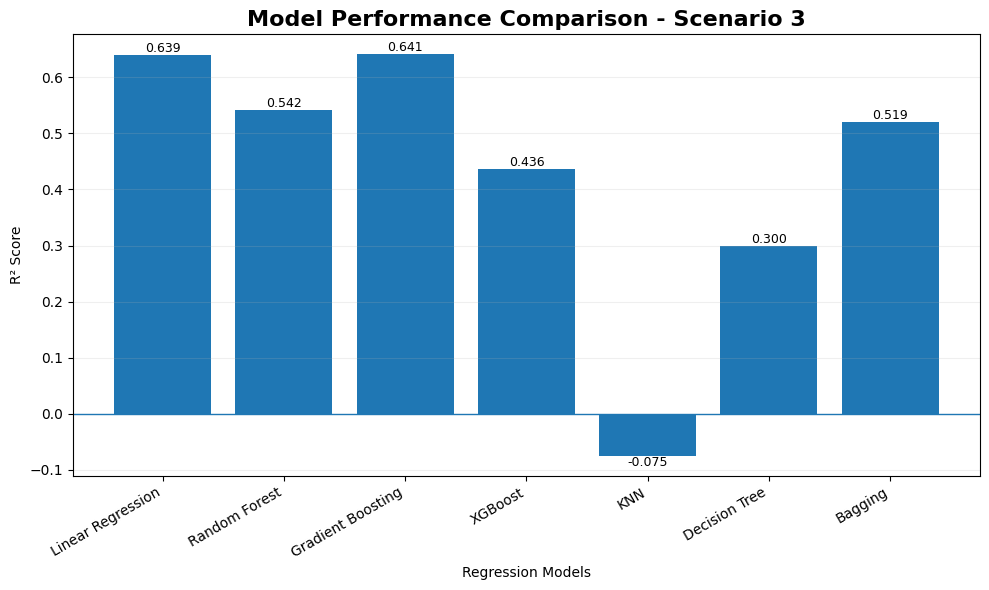

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s3['Model'],
    results_s3['R²']
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title(
    'Model Performance Comparison - Scenario 3',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('R² Score')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(
    bars,
    results_s3['R²']
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center',
        va='bottom' if value >= 0 else 'top',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_r2_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

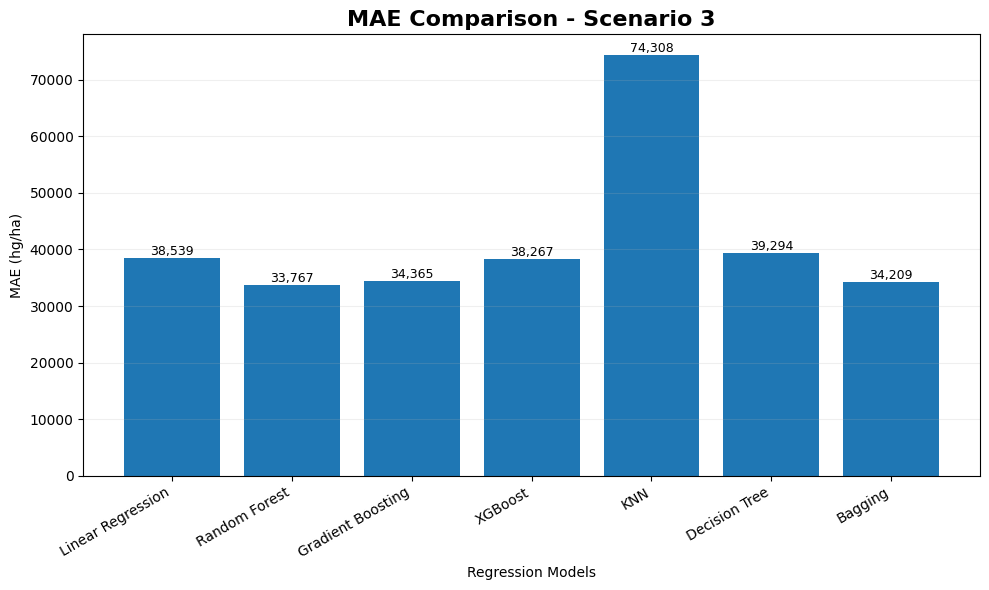

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s3['Model'],
    results_s3['MAE']
)

plt.title(
    'MAE Comparison - Scenario 3',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MAE (hg/ha)')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(
    bars,
    results_s3['MAE']
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_mae_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

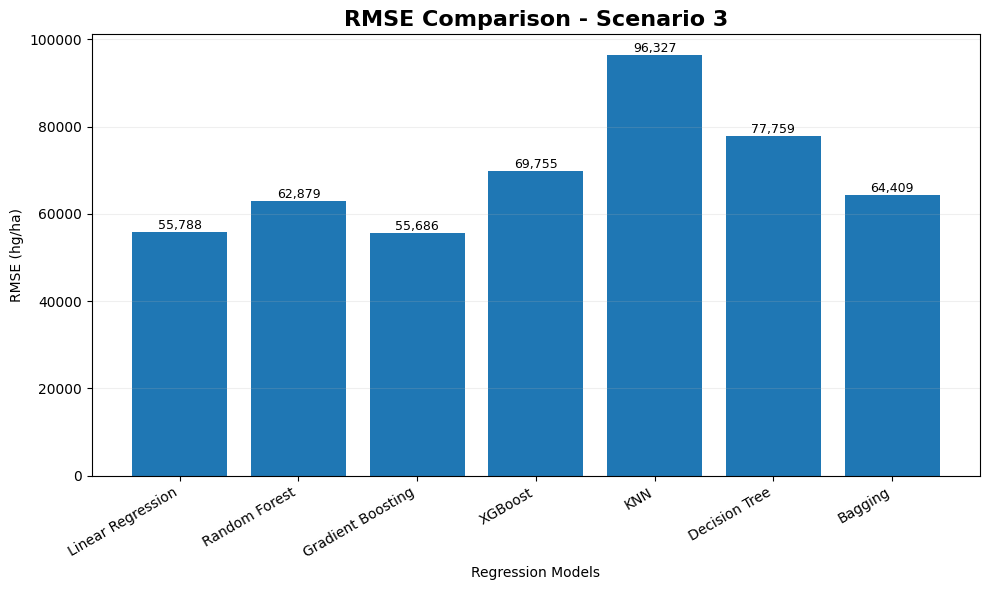

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s3['Model'],
    results_s3['RMSE']
)

plt.title(
    'RMSE Comparison - Scenario 3',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('RMSE (hg/ha)')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(
    bars,
    results_s3['RMSE']
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_rmse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [97]:
features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

feature_names = [
    'Rainfall',
    'Pesticides',
    'Temperature'
]

train_means_s2 = train_data_s2[features].mean()
test_means_s2 = test_data_s2[features].mean()

comparison_s2 = pd.DataFrame({
    'Feature': feature_names,
    'Training Mean (1990–2004)': train_means_s2.values,
    'Test Mean (2005–2013)': test_means_s2.values
})

comparison_s2['Difference'] = (
    comparison_s2['Test Mean (2005–2013)'] -
    comparison_s2['Training Mean (1990–2004)']
)

comparison_s2['Difference (%)'] = (
    comparison_s2['Difference'] /
    comparison_s2['Training Mean (1990–2004)']
) * 100

display(comparison_s2)

,Feature,Training Mean (1990–2004),Test Mean (2005–2013),Difference,Difference (%)
0,Rainfall,1150.208845,1147.837768,-2.371077,-0.206143
1,Pesticides,30568.555883,47170.584870,16602.028987,54.310806
2,Temperature,20.480297,20.637227,0.156929,0.766246


In [98]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=comparison_s2)

https://docs.google.com/spreadsheets/d/19Rp1DWwpvg-IpBcvYYeaqpP2MSuQCXnqJWY_MqQvl9Y/edit#gid=0


In [99]:
print("=== SCENARIO 2 MODEL RESULTS ===")
display(results_s2)

print("\n=== SCENARIO 2 FEATURE SHIFT ===")
display(comparison_s2)

=== SCENARIO 2 MODEL RESULTS ===


,Model,MAE,MSE,RMSE,MAPE,R²
0,Linear Regression,37659.108881,3.414813e+09,58436.400744,91.501034,0.604122
1,Random Forest,13765.053562,8.454614e+08,29076.819590,21.208509,0.901986
2,Gradient Boosting,25325.939308,1.828357e+09,42759.290925,49.546271,0.788039
3,XGBoost,15288.160156,9.135677e+08,30225.283191,27.330826,0.894090
4,KNN,60470.332402,7.935143e+09,89079.418701,184.204310,0.080082
5,Decision Tree,15087.500672,1.052193e+09,32437.518089,24.004012,0.878020
6,Bagging,13745.707499,8.460969e+08,29087.744349,21.161810,0.901912



=== SCENARIO 2 FEATURE SHIFT ===


,Feature,Training Mean (1990–2004),Test Mean (2005–2013),Difference,Difference (%)
0,Rainfall,1150.208845,1147.837768,-2.371077,-0.206143
1,Pesticides,30568.555883,47170.584870,16602.028987,54.310806
2,Temperature,20.480297,20.637227,0.156929,0.766246


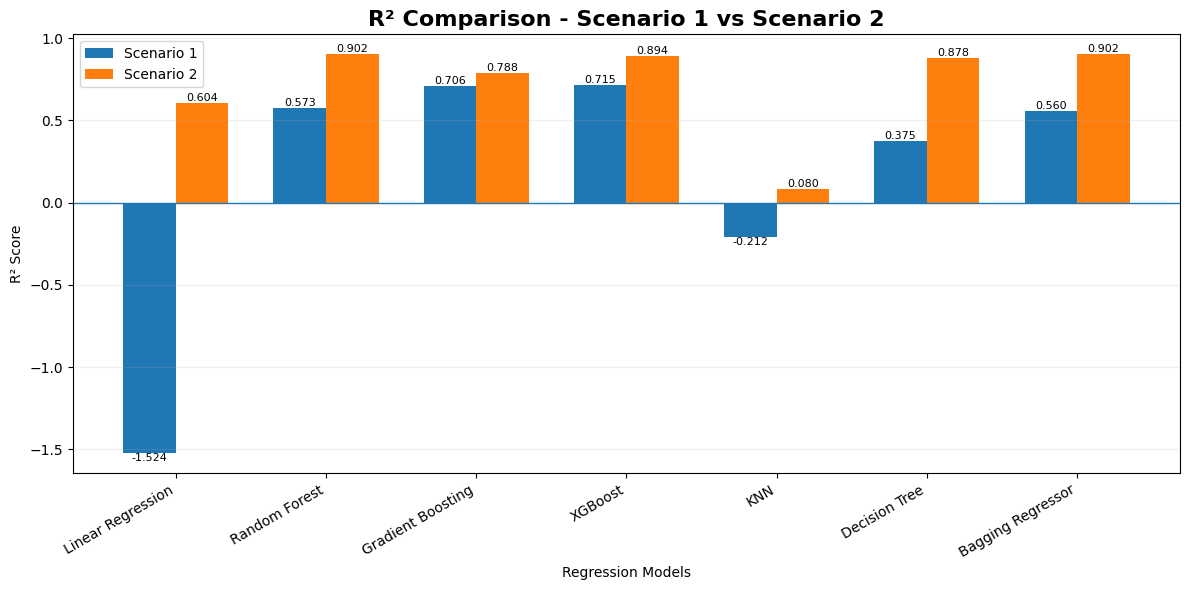

In [100]:
import matplotlib.pyplot as plt
import numpy as np

models = results['Model']

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width/2,
    results['R²'],
    width,
    label='Scenario 1'
)

bars2 = plt.bar(
    x + width/2,
    results_s2['R²'],
    width,
    label='Scenario 2'
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title(
    'R² Comparison - Scenario 1 vs Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('R² Score')

plt.xticks(
    x,
    models,
    rotation=30,
    ha='right'
)

plt.legend()
plt.grid(axis='y', alpha=0.2)

for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f'{value:.3f}',
            ha='center',
            va='bottom' if value >= 0 else 'top',
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    'scenario1_vs_scenario2_r2_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

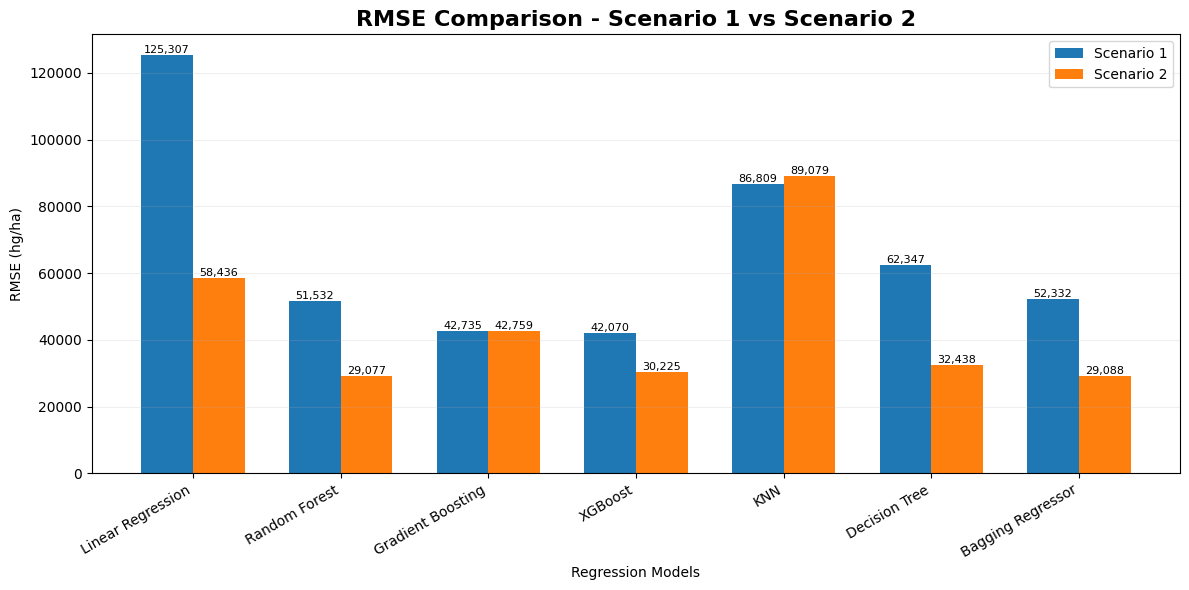

In [101]:
import matplotlib.pyplot as plt
import numpy as np

models = results['Model']

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width / 2,
    results['RMSE'],
    width,
    label='Scenario 1'
)

bars2 = plt.bar(
    x + width / 2,
    results_s2['RMSE'],
    width,
    label='Scenario 2'
)

plt.title(
    'RMSE Comparison - Scenario 1 vs Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('RMSE (hg/ha)')

plt.xticks(
    x,
    models,
    rotation=30,
    ha='right'
)

plt.legend()
plt.grid(axis='y', alpha=0.2)

for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f'{value:,.0f}',
            ha='center',
            va='bottom',
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    'scenario1_vs_scenario2_rmse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

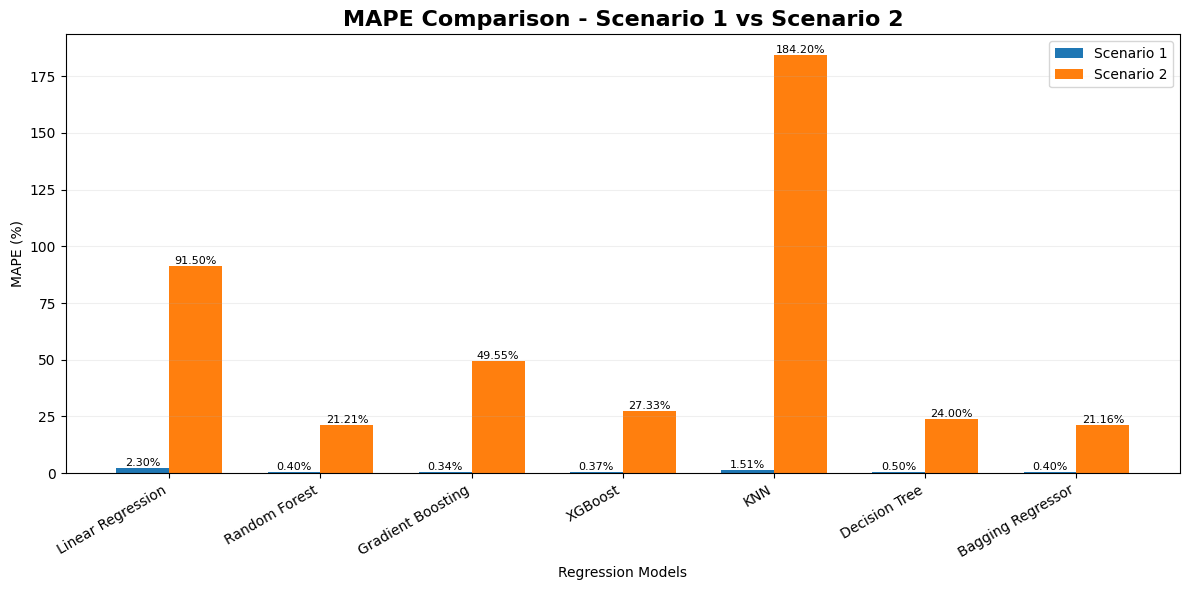

In [102]:
import matplotlib.pyplot as plt
import numpy as np

models = results['Model']

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width / 2,
    results['MAPE'],
    width,
    label='Scenario 1'
)

bars2 = plt.bar(
    x + width / 2,
    results_s2['MAPE'],
    width,
    label='Scenario 2'
)

plt.title(
    'MAPE Comparison - Scenario 1 vs Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MAPE (%)')

plt.xticks(
    x,
    models,
    rotation=30,
    ha='right'
)

plt.legend()
plt.grid(axis='y', alpha=0.2)

for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f'{value:.2f}%',
            ha='center',
            va='bottom',
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    'scenario1_vs_scenario2_mape_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

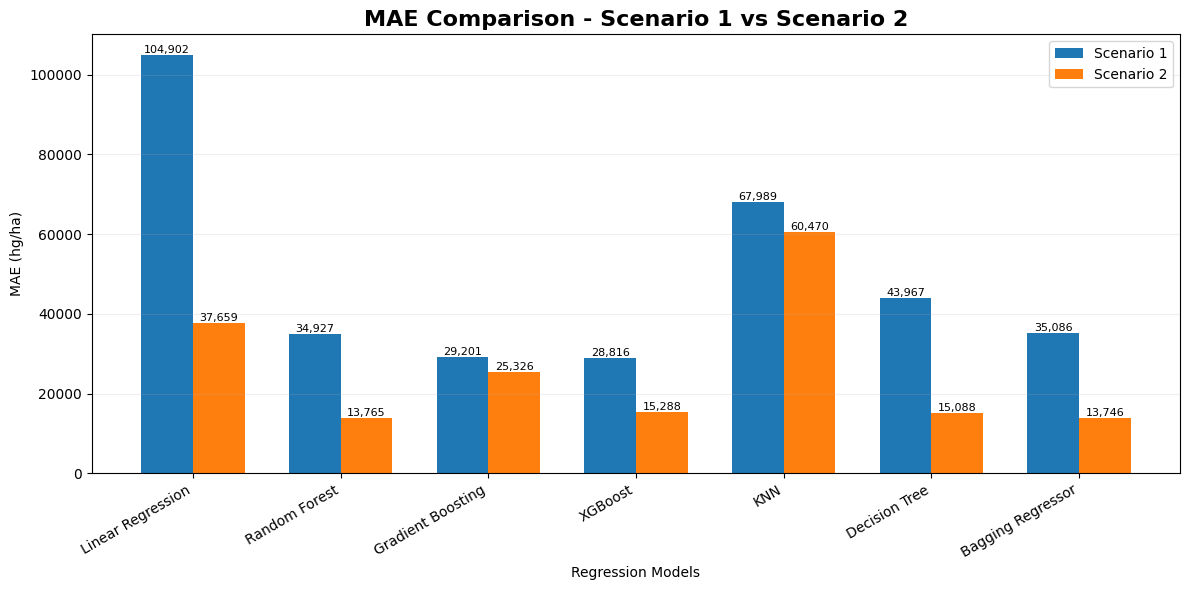

In [103]:
import matplotlib.pyplot as plt
import numpy as np

models = results['Model']

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width / 2,
    results['MAE'],
    width,
    label='Scenario 1'
)

bars2 = plt.bar(
    x + width / 2,
    results_s2['MAE'],
    width,
    label='Scenario 2'
)

plt.title(
    'MAE Comparison - Scenario 1 vs Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MAE (hg/ha)')

plt.xticks(
    x,
    models,
    rotation=30,
    ha='right'
)

plt.legend()
plt.grid(axis='y', alpha=0.2)

for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f'{value:,.0f}',
            ha='center',
            va='bottom',
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    'scenario1_vs_scenario2_mae_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

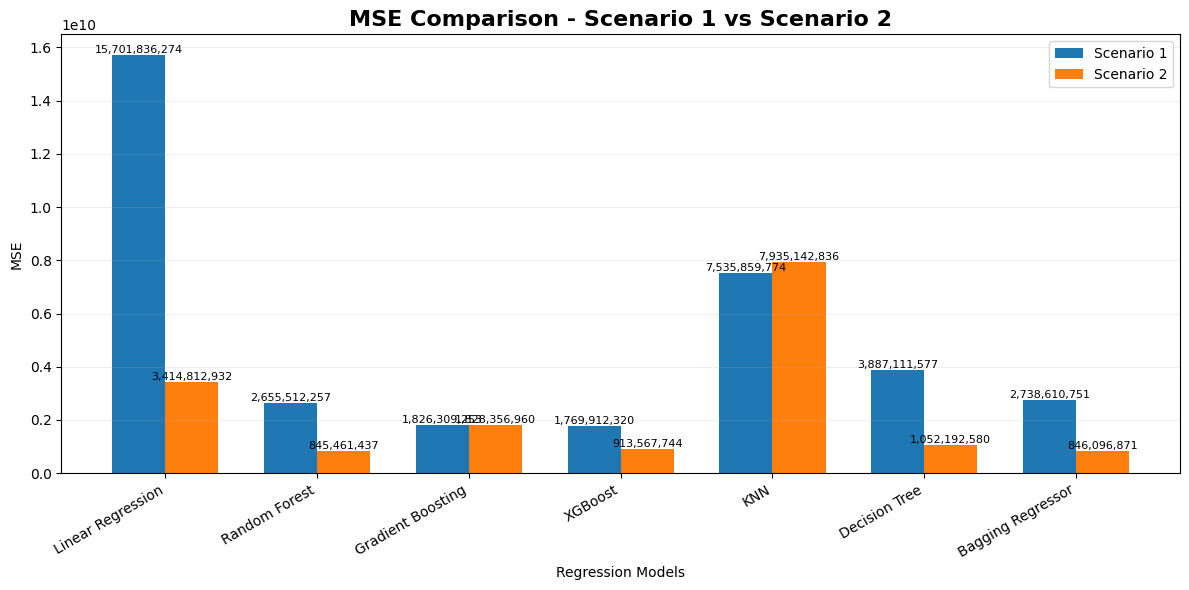

In [104]:
import matplotlib.pyplot as plt
import numpy as np

models = results['Model']

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width / 2,
    results['MSE'],
    width,
    label='Scenario 1'
)

bars2 = plt.bar(
    x + width / 2,
    results_s2['MSE'],
    width,
    label='Scenario 2'
)

plt.title(
    'MSE Comparison - Scenario 1 vs Scenario 2',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MSE')

plt.xticks(
    x,
    models,
    rotation=30,
    ha='right'
)

plt.legend()
plt.grid(axis='y', alpha=0.2)

for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f'{value:,.0f}',
            ha='center',
            va='bottom',
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    'scenario1_vs_scenario2_mse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [105]:
import pandas as pd

comparison_r2 = pd.DataFrame({
    'Model': results['Model'],
    'Scenario 1 R²': results['R²'],
    'Scenario 2 R²': results_s2['R²']
})

comparison_r2['R² Change (S1 - S2)'] = (
    comparison_r2['Scenario 1 R²'] -
    comparison_r2['Scenario 2 R²']
)

display(comparison_r2)

,Model,Scenario 1 R²,Scenario 2 R²,R² Change (S1 - S2)
0,Linear Regression,-1.524422,0.604122,-2.128545
1,Random Forest,0.573067,0.901986,-0.328919
2,Gradient Boosting,0.706380,0.788039,-0.081660
3,XGBoost,0.715447,0.894090,-0.178644
4,KNN,-0.211559,0.080082,-0.291641
5,Decision Tree,0.375060,0.878020,-0.502960
6,Bagging Regressor,0.559707,0.901912,-0.342205


In [106]:
comparison_rmse = pd.DataFrame({
    'Model': results['Model'],
    'Scenario 1 RMSE': results['RMSE'],
    'Scenario 2 RMSE': results_s2['RMSE']
})

comparison_rmse['RMSE Change (S1 - S2)'] = (
    comparison_rmse['Scenario 1 RMSE'] -
    comparison_rmse['Scenario 2 RMSE']
)

display(comparison_rmse)

,Model,Scenario 1 RMSE,Scenario 2 RMSE,RMSE Change (S1 - S2)
0,Linear Regression,125306.968178,58436.400744,66870.567435
1,Random Forest,51531.662662,29076.819590,22454.843072
2,Gradient Boosting,42735.339630,42759.290925,-23.951295
3,XGBoost,42070.325884,30225.283191,11845.042693
4,KNN,86809.329994,89079.418701,-2270.088708
5,Decision Tree,62346.704624,32437.518089,29909.186535
6,Bagging Regressor,52331.737510,29087.744349,23243.993161


In [107]:
comparison_mape = pd.DataFrame({
    'Model': results['Model'],
    'Scenario 1 MAPE': results['MAPE'],
    'Scenario 2 MAPE': results_s2['MAPE']
})

comparison_mape['MAPE Change (S1 - S2)'] = (
    comparison_mape['Scenario 1 MAPE'] -
    comparison_mape['Scenario 2 MAPE']
)

display(comparison_mape)

,Model,Scenario 1 MAPE,Scenario 2 MAPE,MAPE Change (S1 - S2)
0,Linear Regression,2.297239,91.501034,-89.203795
1,Random Forest,0.403738,21.208509,-20.804771
2,Gradient Boosting,0.336557,49.546271,-49.209714
3,XGBoost,0.371005,27.330826,-26.959822
4,KNN,1.506653,184.204310,-182.697656
5,Decision Tree,0.504499,24.004012,-23.499513
6,Bagging Regressor,0.404468,21.161810,-20.757342


In [108]:
comparison_mae = pd.DataFrame({
    'Model': results['Model'],
    'Scenario 1 MAE': results['MAE'],
    'Scenario 2 MAE': results_s2['MAE']
})

comparison_mae['MAE Change (S1 - S2)'] = (
    comparison_mae['Scenario 1 MAE'] -
    comparison_mae['Scenario 2 MAE']
)

display(comparison_mae)

,Model,Scenario 1 MAE,Scenario 2 MAE,MAE Change (S1 - S2)
0,Linear Regression,104902.297395,37659.108881,67243.188514
1,Random Forest,34926.988889,13765.053562,21161.935327
2,Gradient Boosting,29200.892349,25325.939308,3874.953041
3,XGBoost,28816.449219,15288.160156,13528.289062
4,KNN,67988.652514,60470.332402,7518.320112
5,Decision Tree,43967.114836,15087.500672,28879.614164
6,Bagging Regressor,35085.777770,13745.707499,21340.070270


In [109]:
comparison_mse = pd.DataFrame({
    'Model': results['Model'],
    'Scenario 1 MSE': results['MSE'],
    'Scenario 2 MSE': results_s2['MSE']
})

comparison_mse['MSE Change (S1 - S2)'] = (
    comparison_mse['Scenario 1 MSE'] -
    comparison_mse['Scenario 2 MSE']
)

display(comparison_mse)

,Model,Scenario 1 MSE,Scenario 2 MSE,MSE Change (S1 - S2)
0,Linear Regression,1.570184e+10,3.414813e+09,1.228702e+10
1,Random Forest,2.655512e+09,8.454614e+08,1.810051e+09
2,Gradient Boosting,1.826309e+09,1.828357e+09,-2.047707e+06
3,XGBoost,1.769912e+09,9.135677e+08,8.563446e+08
4,KNN,7.535860e+09,7.935143e+09,-3.992831e+08
5,Decision Tree,3.887112e+09,1.052193e+09,2.834919e+09
6,Bagging Regressor,2.738611e+09,8.460969e+08,1.892514e+09


In [110]:
overall_comparison = pd.DataFrame({
    'Model': results['Model'],

    'S1 R²': results['R²'],
    'S2 R²': results_s2['R²'],

    'S1 RMSE': results['RMSE'],
    'S2 RMSE': results_s2['RMSE'],

    'S1 MAPE': results['MAPE'],
    'S2 MAPE': results_s2['MAPE'],

    'S1 MAE': results['MAE'],
    'S2 MAE': results_s2['MAE'],

    'S1 MSE': results['MSE'],
    'S2 MSE': results_s2['MSE']
})

display(overall_comparison)

,Model,S1 R²,S2 R²,S1 RMSE,S2 RMSE,S1 MAPE,S2 MAPE,S1 MAE,S2 MAE,S1 MSE,S2 MSE
0,Linear Regression,-1.524422,0.604122,125306.968178,58436.400744,2.297239,91.501034,104902.297395,37659.108881,1.570184e+10,3.414813e+09
1,Random Forest,0.573067,0.901986,51531.662662,29076.819590,0.403738,21.208509,34926.988889,13765.053562,2.655512e+09,8.454614e+08
2,Gradient Boosting,0.706380,0.788039,42735.339630,42759.290925,0.336557,49.546271,29200.892349,25325.939308,1.826309e+09,1.828357e+09
3,XGBoost,0.715447,0.894090,42070.325884,30225.283191,0.371005,27.330826,28816.449219,15288.160156,1.769912e+09,9.135677e+08
4,KNN,-0.211559,0.080082,86809.329994,89079.418701,1.506653,184.204310,67988.652514,60470.332402,7.535860e+09,7.935143e+09
5,Decision Tree,0.375060,0.878020,62346.704624,32437.518089,0.504499,24.004012,43967.114836,15087.500672,3.887112e+09,1.052193e+09
6,Bagging Regressor,0.559707,0.901912,52331.737510,29087.744349,0.404468,21.161810,35085.777770,13745.707499,2.738611e+09,8.460969e+08


In [111]:
test_countries_s3 = ['Brazil', 'Mexico', 'Argentina']

In [112]:
test_countries_s3 = ['Brazil', 'Mexico', 'Argentina']

train_countries_s3 = [
    country
    for country in df['Area'].unique()
    if country not in test_countries_s3
]

train_data_s3 = df[
    df['Area'].isin(train_countries_s3)
].copy()

test_data_s3 = df[
    df['Area'].isin(test_countries_s3)
].copy()

print("Training countries:", train_data_s3['Area'].nunique())
print("Testing countries:", test_data_s3['Area'].nunique())

print(
    "Country overlap:",
    set(train_data_s3['Area'].unique()) &
    set(test_data_s3['Area'].unique())
)

print(
    "Training years:",
    train_data_s3['Year'].min(),
    "to",
    train_data_s3['Year'].max()
)

print(
    "Testing years:",
    test_data_s3['Year'].min(),
    "to",
    test_data_s3['Year'].max()
)

Training countries: 98
Testing countries: 3
Country overlap: set()
Training years: 1990 to 2013
Testing years: 1990 to 2013


In [113]:
train_data_s3 = train_data_s3.drop(
    columns=['Unnamed: 0'],
    errors='ignore'
)

test_data_s3 = test_data_s3.drop(
    columns=['Unnamed: 0'],
    errors='ignore'
)

features_s3 = [
    'Item',
    'Year',
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

X_train_s3 = train_data_s3[features_s3].copy()
X_test_s3 = test_data_s3[features_s3].copy()

y_train_s3 = train_data_s3['hg/ha_yield']
y_test_s3 = test_data_s3['hg/ha_yield']

print("X_train shape:", X_train_s3.shape)
print("X_test shape:", X_test_s3.shape)

print("y_train shape:", y_train_s3.shape)
print("y_test shape:", y_test_s3.shape)

X_train shape: (24125, 5)
X_test shape: (4117, 5)
y_train shape: (24125,)
y_test shape: (4117,)


In [114]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

encoder_s3 = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

train_item_encoded_s3 = encoder_s3.fit_transform(
    X_train_s3[['Item']]
)

test_item_encoded_s3 = encoder_s3.transform(
    X_test_s3[['Item']]
)

encoded_columns_s3 = encoder_s3.get_feature_names_out(['Item'])

train_item_df_s3 = pd.DataFrame(
    train_item_encoded_s3,
    columns=encoded_columns_s3,
    index=X_train_s3.index
)

test_item_df_s3 = pd.DataFrame(
    test_item_encoded_s3,
    columns=encoded_columns_s3,
    index=X_test_s3.index
)

X_train_s3 = X_train_s3.drop(
    columns=['Item']
)

X_test_s3 = X_test_s3.drop(
    columns=['Item']
)

X_train_s3 = pd.concat(
    [X_train_s3, train_item_df_s3],
    axis=1
)

X_test_s3 = pd.concat(
    [X_test_s3, test_item_df_s3],
    axis=1
)

print("Training shape:", X_train_s3.shape)
print("Testing shape:", X_test_s3.shape)
print("Same columns:", list(X_train_s3.columns) == list(X_test_s3.columns))
print("Missing values - train:", X_train_s3.isnull().sum().sum())
print("Missing values - test:", X_test_s3.isnull().sum().sum())
print("All features numeric:", X_train_s3.dtypes.apply(
    lambda x: pd.api.types.is_numeric_dtype(x)
).all())

Training shape: (24125, 14)
Testing shape: (4117, 14)
Same columns: True
Missing values - train: 0
Missing values - test: 0
All features numeric: True


In [115]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    BaggingRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

# 1. Linear Regression
lr_s3 = LinearRegression()
lr_s3.fit(X_train_s3, y_train_s3)
y_pred_lr_s3 = lr_s3.predict(X_test_s3)


# 2. Random Forest
rf_s3 = RandomForestRegressor(
    random_state=42
)
rf_s3.fit(X_train_s3, y_train_s3)
y_pred_rf_s3 = rf_s3.predict(X_test_s3)


# 3. Gradient Boosting
gb_s3 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb_s3.fit(X_train_s3, y_train_s3)
y_pred_gb_s3 = gb_s3.predict(X_test_s3)


# 4. XGBoost
xgb_s3 = XGBRegressor(
    random_state=42
)
xgb_s3.fit(X_train_s3, y_train_s3)
y_pred_xgb_s3 = xgb_s3.predict(X_test_s3)


# 5. KNN
knn_s3 = KNeighborsRegressor(
    n_neighbors=5
)
knn_s3.fit(X_train_s3, y_train_s3)
y_pred_knn_s3 = knn_s3.predict(X_test_s3)


# 6. Decision Tree
dt_s3 = DecisionTreeRegressor(
    random_state=42
)
dt_s3.fit(X_train_s3, y_train_s3)
y_pred_dt_s3 = dt_s3.predict(X_test_s3)


# 7. Bagging
bag_s3 = BaggingRegressor(
    n_estimators=150,
    random_state=42
)
bag_s3.fit(X_train_s3, y_train_s3)
y_pred_bag_s3 = bag_s3.predict(X_test_s3)


print("All 7 Scenario 3 models trained successfully.")

All 7 Scenario 3 models trained successfully.


In [116]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

predictions_s3 = {
    'Linear Regression': y_pred_lr_s3,
    'Random Forest': y_pred_rf_s3,
    'Gradient Boosting': y_pred_gb_s3,
    'XGBoost': y_pred_xgb_s3,
    'KNN': y_pred_knn_s3,
    'Decision Tree': y_pred_dt_s3,
    'Bagging': y_pred_bag_s3
}

results_s3 = []

for model_name, predictions in predictions_s3.items():

    mae = mean_absolute_error(
        y_test_s3,
        predictions
    )

    mse = mean_squared_error(
        y_test_s3,
        predictions
    )

    rmse = np.sqrt(mse)

    non_zero = y_test_s3 != 0

    mape = np.mean(
        np.abs(
            (y_test_s3[non_zero] - predictions[non_zero])
            / y_test_s3[non_zero]
        )
    ) * 100

    r2 = r2_score(
        y_test_s3,
        predictions
    )

    results_s3.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape,
        'R²': r2
    })

results_s3 = pd.DataFrame(results_s3)

display(results_s3)

,Model,MAE,MSE,RMSE,MAPE,R²
0,Linear Regression,68091.137258,8.369921e+09,91487.273036,146.683500,-0.690401
1,Random Forest,33473.975217,3.311493e+09,57545.575964,42.854615,0.331206
2,Gradient Boosting,29148.733311,1.899347e+09,43581.503363,39.974216,0.616405
3,XGBoost,33867.398438,3.017149e+09,54928.580247,46.447366,0.390652
4,KNN,63090.822638,6.264201e+09,79146.704841,162.638510,-0.265127
5,Decision Tree,47466.207918,5.320089e+09,72938.942058,59.528599,-0.074453
6,Bagging,33285.272703,3.354084e+09,57914.451172,42.660709,0.322605


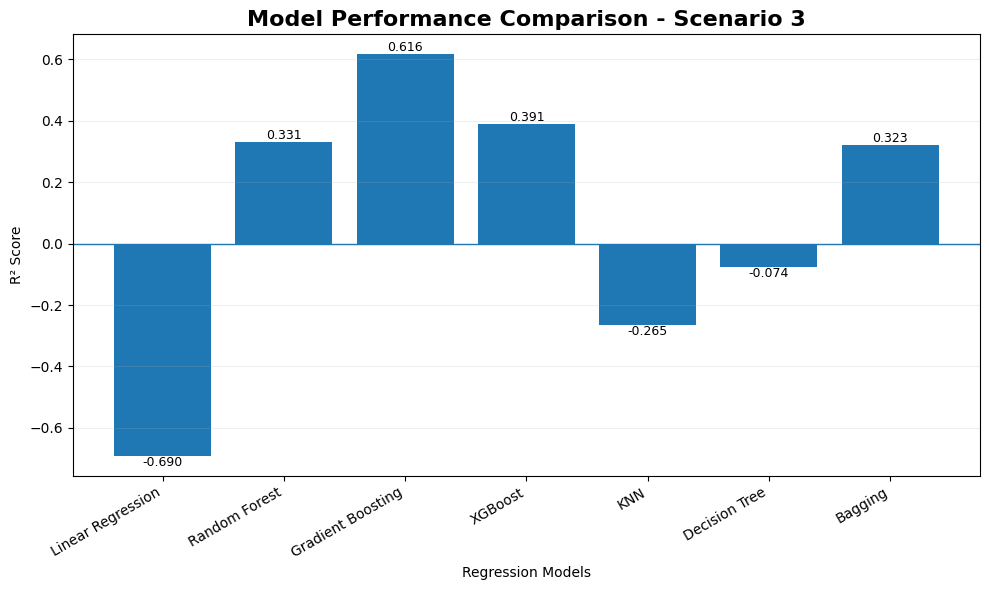

In [117]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s3['Model'],
    results_s3['R²']
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title(
    'Model Performance Comparison - Scenario 3',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('R² Score')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(bars, results_s3['R²']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.3f}',
        ha='center',
        va='bottom' if value >= 0 else 'top',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_r2_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

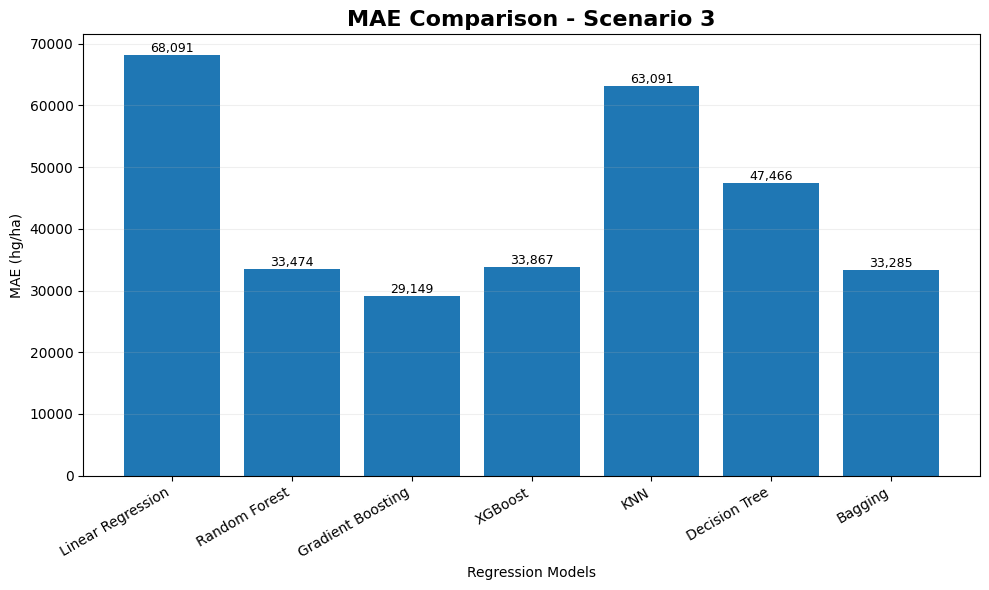

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s3['Model'],
    results_s3['MAE']
)

plt.title(
    'MAE Comparison - Scenario 3',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MAE (hg/ha)')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(bars, results_s3['MAE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_mae_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

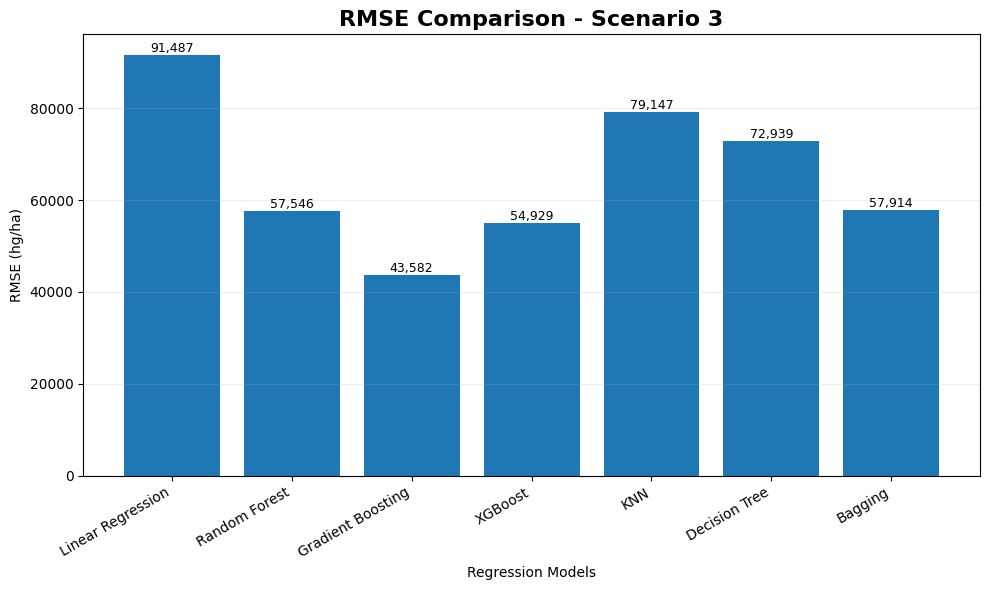

In [119]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s3['Model'],
    results_s3['RMSE']
)

plt.title(
    'RMSE Comparison - Scenario 3',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('RMSE (hg/ha)')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(bars, results_s3['RMSE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_rmse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

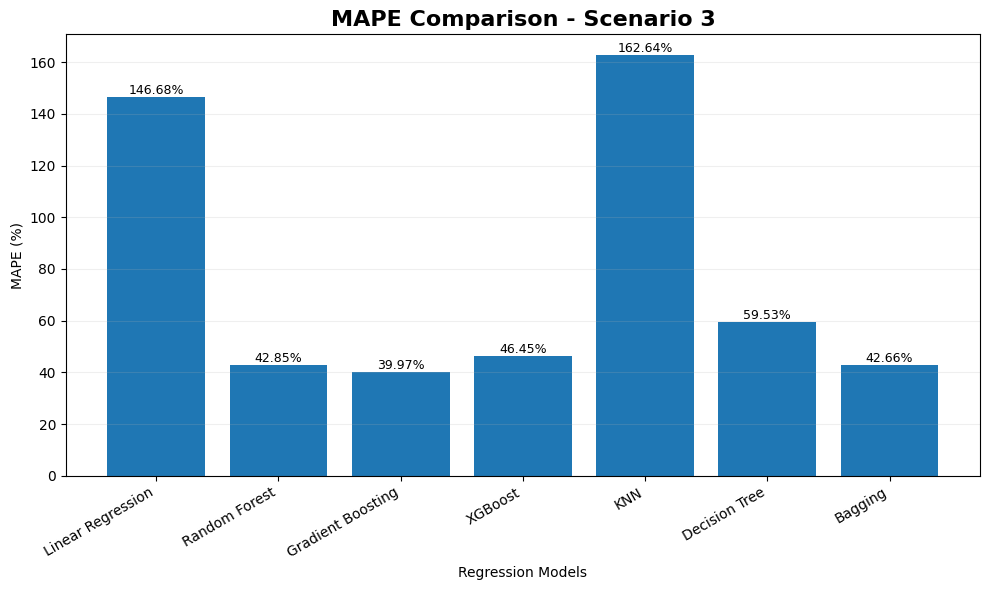

In [120]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s3['Model'],
    results_s3['MAPE']
)

plt.title(
    'MAPE Comparison - Scenario 3',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MAPE (%)')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(bars, results_s3['MAPE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.2f}%',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_mape_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

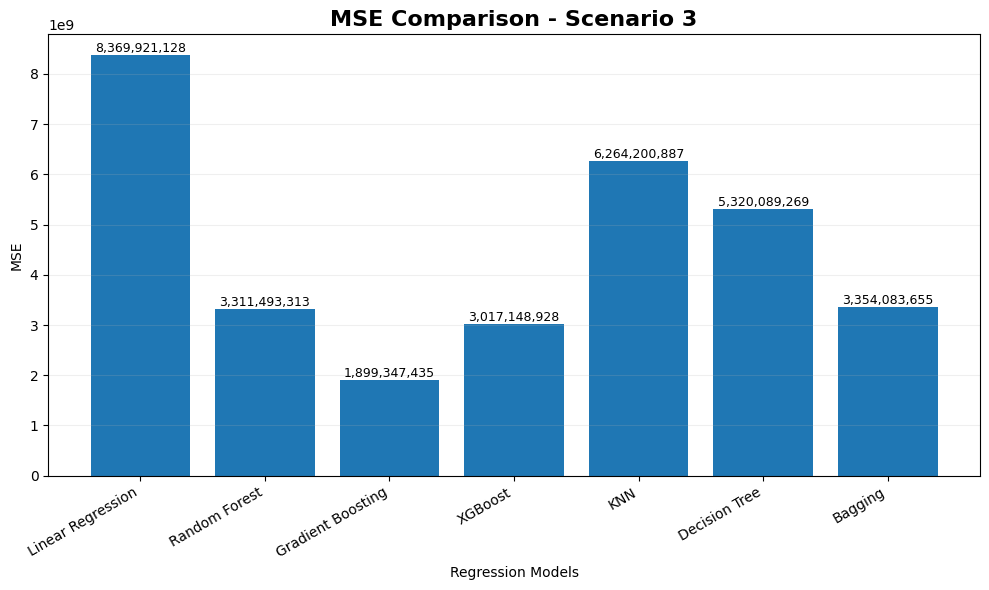

In [121]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_s3['Model'],
    results_s3['MSE']
)

plt.title(
    'MSE Comparison - Scenario 3',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Regression Models')
plt.ylabel('MSE')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(bars, results_s3['MSE']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_mse_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

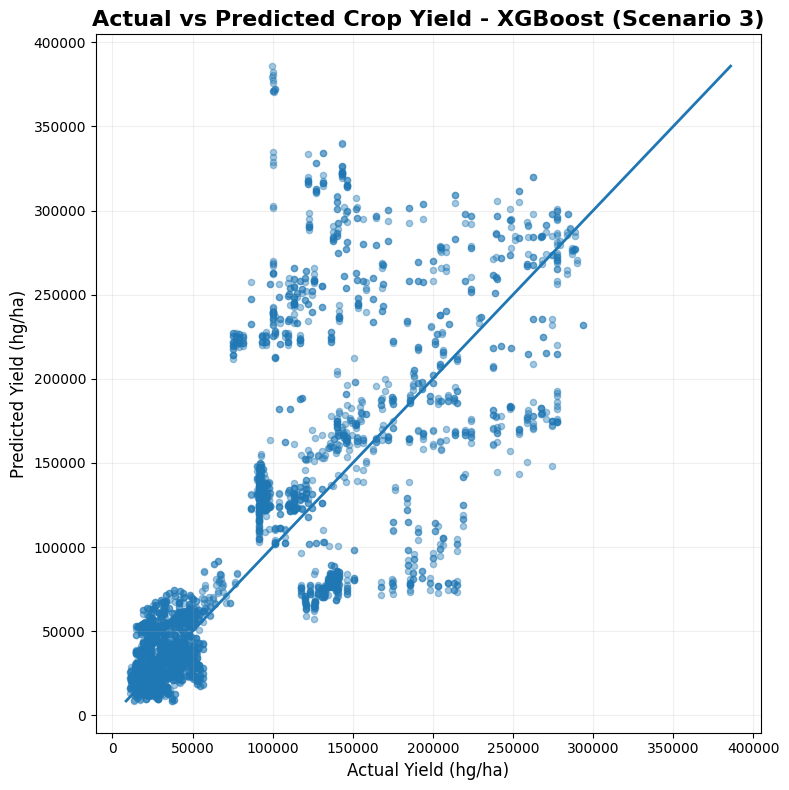

In [122]:
import matplotlib.pyplot as plt
import numpy as np

actual = np.array(y_test_s3)
predicted = np.array(y_pred_xgb_s3)

plt.figure(figsize=(8, 8))

plt.scatter(
    actual,
    predicted,
    alpha=0.4,
    s=20
)

min_value = min(
    actual.min(),
    predicted.min()
)

max_value = max(
    actual.max(),
    predicted.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linewidth=2
)

plt.title(
    'Actual vs Predicted Crop Yield - XGBoost (Scenario 3)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel(
    'Actual Yield (hg/ha)',
    fontsize=12
)

plt.ylabel(
    'Predicted Yield (hg/ha)',
    fontsize=12
)

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    'scenario3_actual_vs_predicted_xgboost.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

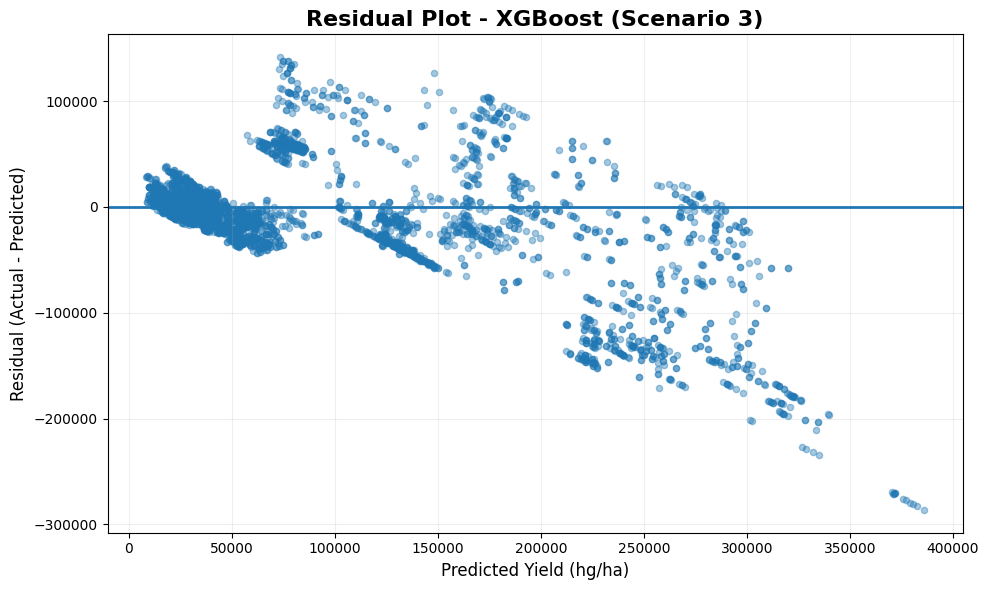

In [123]:
import matplotlib.pyplot as plt
import numpy as np

actual = np.array(y_test_s3)
predicted = np.array(y_pred_xgb_s3)

residuals = actual - predicted

plt.figure(figsize=(10, 6))

plt.scatter(
    predicted,
    residuals,
    alpha=0.4,
    s=20
)

plt.axhline(
    y=0,
    linewidth=2
)

plt.title(
    'Residual Plot - XGBoost (Scenario 3)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel(
    'Predicted Yield (hg/ha)',
    fontsize=12
)

plt.ylabel(
    'Residual (Actual - Predicted)',
    fontsize=12
)

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    'scenario3_residual_plot_xgboost.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [124]:
error_df_s3 = test_data_s3[
    ['Area', 'Item', 'Year']
].copy()

error_df_s3['Actual'] = y_test_s3.values
error_df_s3['Predicted'] = y_pred_xgb_s3

error_df_s3['Absolute_Error'] = (
    abs(
        error_df_s3['Actual'] -
        error_df_s3['Predicted']
    )
)

error_df_s3['Percentage_Error'] = (
    error_df_s3['Absolute_Error'] /
    error_df_s3['Actual'].replace(0, np.nan)
) * 100

country_error_s3 = (
    error_df_s3
    .groupby('Area')
    .agg(
        MAE=('Absolute_Error', 'mean'),
        MAPE=('Percentage_Error', 'mean')
    )
    .reset_index()
    .sort_values('MAE', ascending=False)
)

display(country_error_s3)

,Area,MAE,MAPE
2,Mexico,38855.174582,46.329409
0,Argentina,33652.205126,37.108490
1,Brazil,30677.758307,48.032935


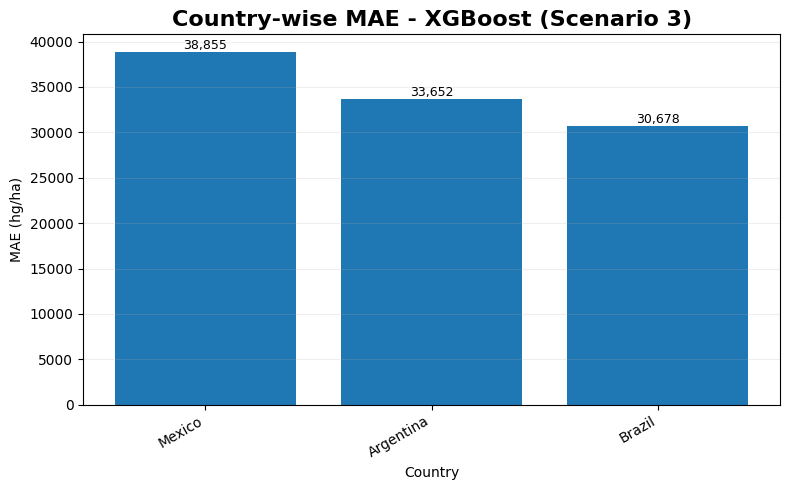

In [125]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(
    country_error_s3['Area'],
    country_error_s3['MAE']
)

plt.title(
    'Country-wise MAE - XGBoost (Scenario 3)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Country')
plt.ylabel('MAE (hg/ha)')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(
    bars,
    country_error_s3['MAE']
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_country_wise_mae.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [126]:
crop_error_s3 = (
    error_df_s3
    .groupby('Item')
    .agg(
        MAE=('Absolute_Error', 'mean'),
        MAPE=('Percentage_Error', 'mean')
    )
    .reset_index()
    .sort_values('MAE', ascending=False)
)

display(crop_error_s3)

,Item,MAE,MAPE
0,Cassava,98936.225721,86.989775
6,Sweet potatoes,56872.126747,41.501652
2,Potatoes,53802.707363,28.024965
8,Yams,38896.552742,41.989536
3,"Rice, paddy",16414.318525,50.594243
4,Sorghum,14245.090280,63.342768
1,Maize,11547.701971,39.402354
7,Wheat,10901.845655,36.039743
5,Soybeans,5584.862189,28.018486


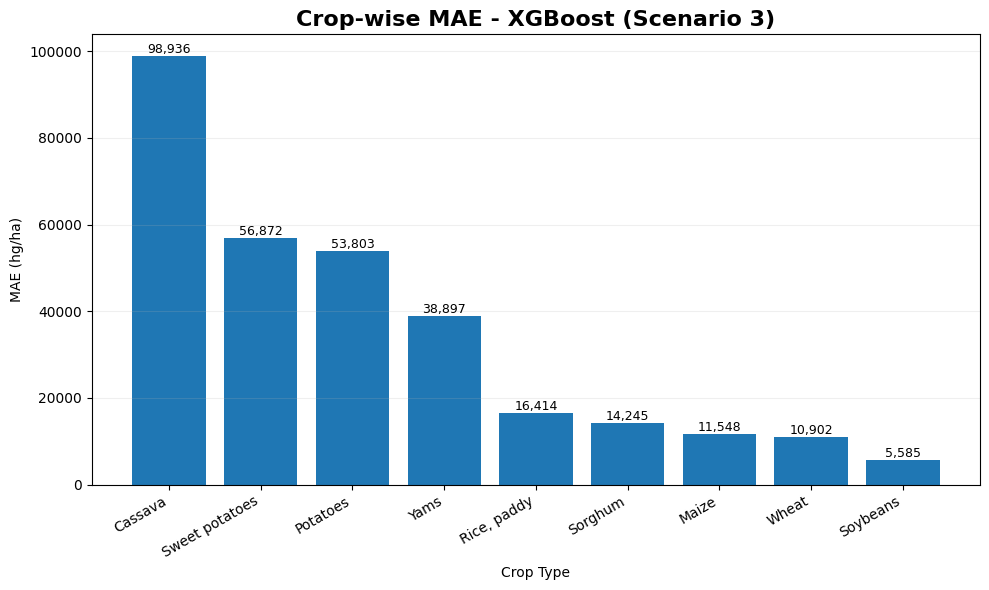

In [127]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    crop_error_s3['Item'],
    crop_error_s3['MAE']
)

plt.title(
    'Crop-wise MAE - XGBoost (Scenario 3)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Crop Type')
plt.ylabel('MAE (hg/ha)')

plt.xticks(
    rotation=30,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

for bar, value in zip(
    bars,
    crop_error_s3['MAE']
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    'scenario3_crop_wise_mae.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

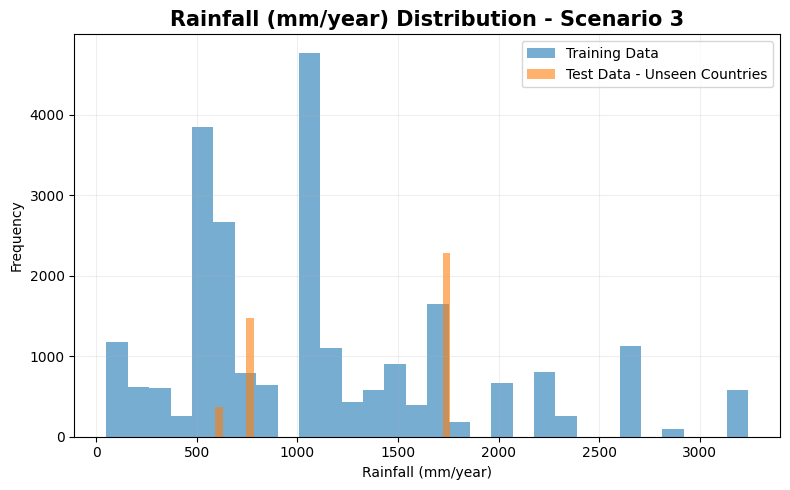

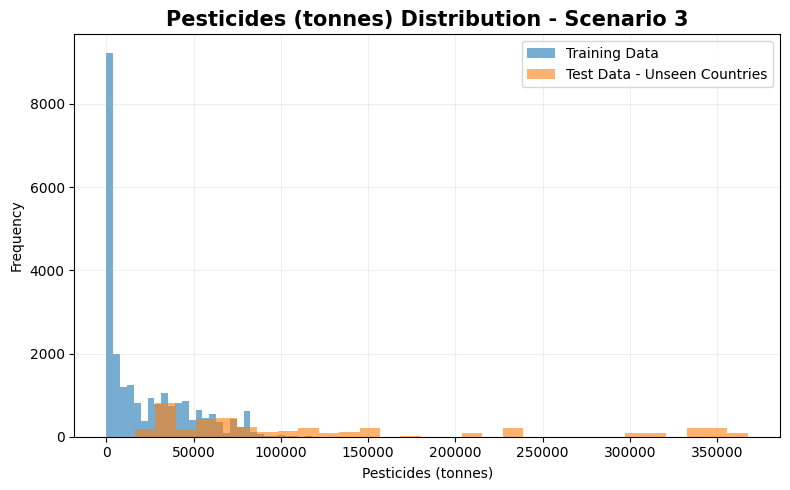

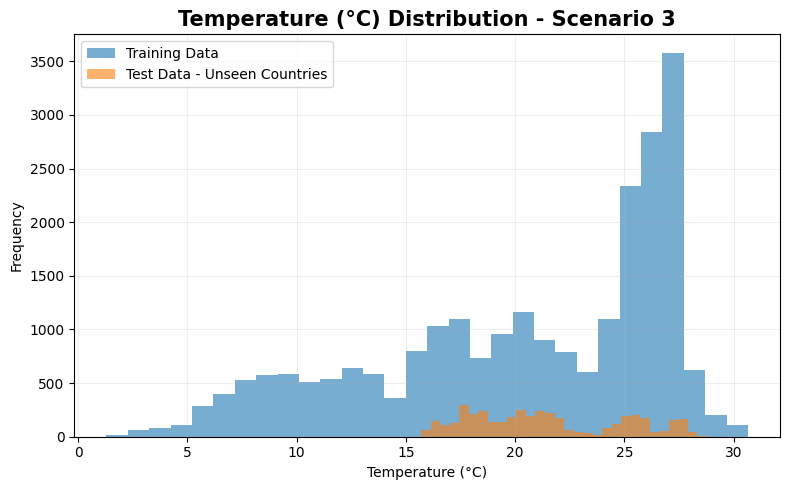

In [128]:
import matplotlib.pyplot as plt

features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

feature_names = [
    'Rainfall (mm/year)',
    'Pesticides (tonnes)',
    'Temperature (°C)'
]

for feature, name in zip(features, feature_names):

    plt.figure(figsize=(8, 5))

    plt.hist(
        train_data_s3[feature].dropna(),
        bins=30,
        alpha=0.6,
        label='Training Data'
    )

    plt.hist(
        test_data_s3[feature].dropna(),
        bins=30,
        alpha=0.6,
        label='Test Data - Unseen Countries'
    )

    plt.title(
        f'{name} Distribution - Scenario 3',
        fontsize=15,
        fontweight='bold'
    )

    plt.xlabel(name)
    plt.ylabel('Frequency')

    plt.legend()
    plt.grid(alpha=0.2)

    plt.tight_layout()

    plt.savefig(
        f'scenario3_{feature}_distribution.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

In [129]:
features = [
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp'
]

feature_names = [
    'Rainfall',
    'Pesticides',
    'Temperature'
]

train_means_s3 = train_data_s3[features].mean()
test_means_s3 = test_data_s3[features].mean()

comparison_s3 = pd.DataFrame({
    'Feature': feature_names,
    'Training Mean': train_means_s3.values,
    'Test Mean (Unseen Countries)': test_means_s3.values
})

comparison_s3['Difference'] = (
    comparison_s3['Test Mean (Unseen Countries)'] -
    comparison_s3['Training Mean']
)

comparison_s3['Difference (%)'] = (
    comparison_s3['Difference'] /
    comparison_s3['Training Mean']
) * 100

display(comparison_s3)

,Feature,Training Mean,Test Mean (Unseen Countries),Difference,Difference (%)
0,Rainfall,1123.671627,1297.804469,174.132842,15.496773
1,Pesticides,21813.748576,126516.732883,104702.984307,479.986207
2,Temperature,20.392086,21.424770,1.032684,5.064142


In [130]:
overall_3_scenarios = pd.DataFrame({
    'Model': results['Model'],

    'S1 R²': results['R²'],
    'S2 R²': results_s2['R²'],
    'S3 R²': results_s3['R²'],

    'S1 RMSE': results['RMSE'],
    'S2 RMSE': results_s2['RMSE'],
    'S3 RMSE': results_s3['RMSE'],

    'S1 MAPE': results['MAPE'],
    'S2 MAPE': results_s2['MAPE'],
    'S3 MAPE': results_s3['MAPE'],

    'S1 MAE': results['MAE'],
    'S2 MAE': results_s2['MAE'],
    'S3 MAE': results_s3['MAE'],

    'S1 MSE': results['MSE'],
    'S2 MSE': results_s2['MSE'],
    'S3 MSE': results_s3['MSE']
})

display(overall_3_scenarios)

,Model,S1 R²,S2 R²,S3 R²,S1 RMSE,S2 RMSE,S3 RMSE,S1 MAPE,S2 MAPE,S3 MAPE,S1 MAE,S2 MAE,S3 MAE,S1 MSE,S2 MSE,S3 MSE
0,Linear Regression,-1.524422,0.604122,-0.690401,125306.968178,58436.400744,91487.273036,2.297239,91.501034,146.683500,104902.297395,37659.108881,68091.137258,1.570184e+10,3.414813e+09,8.369921e+09
1,Random Forest,0.573067,0.901986,0.331206,51531.662662,29076.819590,57545.575964,0.403738,21.208509,42.854615,34926.988889,13765.053562,33473.975217,2.655512e+09,8.454614e+08,3.311493e+09
2,Gradient Boosting,0.706380,0.788039,0.616405,42735.339630,42759.290925,43581.503363,0.336557,49.546271,39.974216,29200.892349,25325.939308,29148.733311,1.826309e+09,1.828357e+09,1.899347e+09
3,XGBoost,0.715447,0.894090,0.390652,42070.325884,30225.283191,54928.580247,0.371005,27.330826,46.447366,28816.449219,15288.160156,33867.398438,1.769912e+09,9.135677e+08,3.017149e+09
4,KNN,-0.211559,0.080082,-0.265127,86809.329994,89079.418701,79146.704841,1.506653,184.204310,162.638510,67988.652514,60470.332402,63090.822638,7.535860e+09,7.935143e+09,6.264201e+09
5,Decision Tree,0.375060,0.878020,-0.074453,62346.704624,32437.518089,72938.942058,0.504499,24.004012,59.528599,43967.114836,15087.500672,47466.207918,3.887112e+09,1.052193e+09,5.320089e+09
6,Bagging Regressor,0.559707,0.901912,0.322605,52331.737510,29087.744349,57914.451172,0.404468,21.161810,42.660709,35085.777770,13745.707499,33285.272703,2.738611e+09,8.460969e+08,3.354084e+09


In [131]:
final_model_comparison = pd.DataFrame({
    'Model': results['Model'],

    'S1 R²': results['R²'],
    'S2 R²': results_s2['R²'],
    'S3 R²': results_s3['R²'],

    'S1 RMSE': results['RMSE'],
    'S2 RMSE': results_s2['RMSE'],
    'S3 RMSE': results_s3['RMSE'],

    'S1 MAPE': results['MAPE'],
    'S2 MAPE': results_s2['MAPE'],
    'S3 MAPE': results_s3['MAPE'],

    'S1 MAE': results['MAE'],
    'S2 MAE': results_s2['MAE'],
    'S3 MAE': results_s3['MAE'],

    'S1 MSE': results['MSE'],
    'S2 MSE': results_s2['MSE'],
    'S3 MSE': results_s3['MSE']
})

display(final_model_comparison)

,Model,S1 R²,S2 R²,S3 R²,S1 RMSE,S2 RMSE,S3 RMSE,S1 MAPE,S2 MAPE,S3 MAPE,S1 MAE,S2 MAE,S3 MAE,S1 MSE,S2 MSE,S3 MSE
0,Linear Regression,-1.524422,0.604122,-0.690401,125306.968178,58436.400744,91487.273036,2.297239,91.501034,146.683500,104902.297395,37659.108881,68091.137258,1.570184e+10,3.414813e+09,8.369921e+09
1,Random Forest,0.573067,0.901986,0.331206,51531.662662,29076.819590,57545.575964,0.403738,21.208509,42.854615,34926.988889,13765.053562,33473.975217,2.655512e+09,8.454614e+08,3.311493e+09
2,Gradient Boosting,0.706380,0.788039,0.616405,42735.339630,42759.290925,43581.503363,0.336557,49.546271,39.974216,29200.892349,25325.939308,29148.733311,1.826309e+09,1.828357e+09,1.899347e+09
3,XGBoost,0.715447,0.894090,0.390652,42070.325884,30225.283191,54928.580247,0.371005,27.330826,46.447366,28816.449219,15288.160156,33867.398438,1.769912e+09,9.135677e+08,3.017149e+09
4,KNN,-0.211559,0.080082,-0.265127,86809.329994,89079.418701,79146.704841,1.506653,184.204310,162.638510,67988.652514,60470.332402,63090.822638,7.535860e+09,7.935143e+09,6.264201e+09
5,Decision Tree,0.375060,0.878020,-0.074453,62346.704624,32437.518089,72938.942058,0.504499,24.004012,59.528599,43967.114836,15087.500672,47466.207918,3.887112e+09,1.052193e+09,5.320089e+09
6,Bagging Regressor,0.559707,0.901912,0.322605,52331.737510,29087.744349,57914.451172,0.404468,21.161810,42.660709,35085.777770,13745.707499,33285.272703,2.738611e+09,8.460969e+08,3.354084e+09


In [132]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=final_model_comparison)

https://docs.google.com/spreadsheets/d/15bjyewMBrpGfyGBFC9-rC-0MBqhcRSgJOElGTkjfCjs/edit#gid=0


In [133]:
summary_comparison = pd.DataFrame({
    'Model': results['Model'],

    'Average R²': (
        results['R²'] +
        results_s2['R²'] +
        results_s3['R²']
    ) / 3,

    'Average RMSE': (
        results['RMSE'] +
        results_s2['RMSE'] +
        results_s3['RMSE']
    ) / 3,

    'Average MAPE': (
        results['MAPE'] +
        results_s2['MAPE'] +
        results_s3['MAPE']
    ) / 3,

    'Average MAE': (
        results['MAE'] +
        results_s2['MAE'] +
        results_s3['MAE']
    ) / 3,

    'Average MSE': (
        results['MSE'] +
        results_s2['MSE'] +
        results_s3['MSE']
    ) / 3
})

display(summary_comparison)

,Model,Average R²,Average RMSE,Average MAPE,Average MAE,Average MSE
0,Linear Regression,-0.536900,91743.547319,80.160591,70217.514511,9.162190e+09
1,Random Forest,0.602086,46051.352739,21.488954,27388.672556,2.270822e+09
2,Gradient Boosting,0.703608,43025.377972,29.952348,27891.854989,1.851338e+09
3,XGBoost,0.666730,42408.063108,24.716399,25990.669271,1.900210e+09
4,KNN,-0.132201,85011.817845,116.116491,63849.935851,7.245068e+09
5,Decision Tree,0.392876,55907.721590,28.012370,35506.941142,3.419798e+09
6,Bagging Regressor,0.594741,46444.644344,21.408996,27372.252657,2.312930e+09
